# Module 1 – Advanced Spatial Epidemiology
**Participant notebook (R in Google Colab)**

This notebook contains every code cell of the training manual, in the same order and with the same step numbers, so you can run it alongside the manual. Run the cells from top to bottom; each topic depends on objects created earlier.

Before starting: **Runtime → Change runtime type → Language: R**. Then run the setup cells. When a session resets, run the setup cells again and continue where you were.

Text cells give the step; the manual has the explanations, the expected outputs and the figures, so compare your output with the manual after each cell.

## Setting up: Google Colab and R

In this training we run R inside Google Colab instead of RStudio on your laptop. Colab is a free notebook that runs in your browser on a Google computer. Nothing needs to be installed on your machine, everyone has the same environment, and a facilitator can open your notebook to help. The trade-off is that the Google computer is temporary: when you close the tab for long enough, or after about 12 hours, the session is wiped and packages have to be installed again. Your notebook itself is safe because it is saved in Google Drive; only the temporary computer is wiped.

### Opening an R notebook in Colab

### Getting the training data into Colab

The Google computer behind Colab starts empty every session, so the data pack has to be brought in each time. The facilitators have placed module1_data.zip in Google Drive with a public link, and the R package googledrive can download a public file without any sign-in. Run this cell at the start of every session; it takes under a minute.

In [ ]:
if (!requireNamespace("googledrive", quietly = TRUE)) install.packages("googledrive")
googledrive::drive_deauth()                       # public file: no login needed
file_id <- "1stsezfPO7t1jseBoZjX-ZyCgFCoChuEF"
googledrive::drive_download(googledrive::as_id(file_id),
                            path = "/content/module1_data.zip", overwrite = TRUE)
unzip("/content/module1_data.zip", exdir = "/content/module1_data")

data_dir <- "/content/module1_data"
list.files(data_dir)               # you should see ghana_districts.gpkg, bolga_cases_2024.csv, ...
list.files(file.path(data_dir, "rasters"))

File downloaded:

• module1_data.zip <id: 1stsezfPO7t1jseBoZjX-ZyCgFCoChuEF>

Saved locally as:

• /content/module1_data.zip



[1] "bolga_cases_2024.csv"      "district_indicators.csv"  
[3] "facilities.csv"            "ghana_districts.gpkg"     
[5] "malaria_district_2024.csv" "mis_clusters_2024.csv"    
[7] "rasters"                   "README.txt"

[1] "chirps_2024_01.tif"    "chirps_2024_02.tif"    "chirps_2024_03.tif"   
 [4] "chirps_2024_04.tif"    "chirps_2024_05.tif"    "chirps_2024_06.tif"   
 [7] "chirps_2024_07.tif"    "chirps_2024_08.tif"    "chirps_2024_09.tif"   
[10] "chirps_2024_10.tif"    "chirps_2024_11.tif"    "chirps_2024_12.tif"   
[13] "era5_temp_2024_01.tif" "era5_temp_2024_02.tif" "era5_temp_2024_03.tif"
[16] "era5_temp_2024_04.tif" "era5_temp_2024_05.tif" "era5_temp_2024_06.tif"
[19] "era5_temp_2024_07.tif" "era5_temp_2024_08.tif" "era5_temp_2024_09.tif"
[22] "era5_temp_2024_10.tif" "era5_temp_2024_11.tif" "era5_temp_2024_12.tif"
[25] "ndvi_2024.tif"         "srtm_ghana.tif"        "worldpop_2023.tif"

The file ID is the long string of letters and numbers in the sharing link, between /d/ and /view. The facilitator will write it on the board.

Two other ways to get files in, if the download fails: click the folder icon on the left edge of the Colab screen, then the upload icon, and choose module1_data.zip from your laptop, then run only the unzip line and the lines after it; or, if the zip is on a website, use download.file("https://.../module1_data.zip", "/content/module1_data.zip").

Anything you create during the session lives in /content and disappears when the session ends. To keep a result, write it to a file and download it from the Files panel (hover over the file, click the three dots, choose Download). Create an outputs folder once with dir.create("/content/outputs").

### Installing the packages in Colab

Colab's R runtime already has the tidyverse and sf installed. The spatial analysis packages must be installed at the start of each session. Run this cell first, then get a cup of tea; the first install takes 5 to 10 minutes because some packages are built from source. Do not run anything else until it finishes.

In [ ]:
pkgs <- c("terra", "exactextractr", "spatstat", "spdep", "SpatialEpi", "gstat",
          "scales", "surveillance", "patchwork")
new  <- pkgs[!pkgs %in% rownames(installed.packages())]
if (length(new) > 0) install.packages(new, quiet = TRUE)

library(tidyverse); library(sf); library(terra); library(exactextractr)
library(spatstat); library(spdep); library(SpatialEpi); library(gstat)
library(scales); library(surveillance); library(patchwork)

also installing the dependencies ‘classInt’, ‘polyclip’, ‘spatstat.sparse’, ‘goftest’, ‘abind’, ‘tensor’, ‘wk’, ‘proxy’, ‘xts’, ‘intervals’, ‘raster’, ‘sf’, ‘spatstat.data’, ‘spatstat.univar’, ‘spatstat.geom’, ‘spatstat.random’, ‘spatstat.explore’, ‘spatstat.model’, ‘spatstat.linnet’, ‘spatstat.utils’, ‘spData’, ‘deldir’, ‘units’, ‘s2’, ‘e1071’, ‘sp’, ‘RcppArmadillo’, ‘zoo’, ‘sftime’, ‘spacetime’, ‘stars’, ‘FNN’, ‘polyCub’


── Attaching core tidyverse packages ──────────────────────── tidyverse 2.0.0 ──
✔ dplyr     1.2.1     ✔ readr     2.2.0
✔ forcats   1.0.1     ✔ stringr   1.6.0
✔ ggplot2   4.0.3     ✔ tibble    3.3.1
✔ lubridate 1.9.5     ✔ tidyr     1.3.2
✔ purrr     1.2.2     
── Conflicts ────────────────────────────────────────── tidyverse_conflicts() ──
✖ dplyr::filter() masks stats::filter()
✖ dplyr::lag()    masks stats::lag()
ℹ Use the conflicted package (<http://conflicted.r-lib.org/>) to force all conflicts to become errors
Linking to GEOS 3.12.1, GDAL 3.8.4, PROJ 9.4.0;

If a package fails with a message about a missing system library, run this in a cell and then repeat the install. It adds the system pieces that terra and sf depend on.

In [ ]:
system("apt-get install -y -q libgdal-dev libgeos-dev libproj-dev libudunits2-dev > /dev/null 2>&1")

### Working habits that save time in Colab

### Loading the district map

In [ ]:
districts <- st_read(file.path(data_dir, "ghana_districts.gpkg"), quiet = TRUE)
st_crs(districts)$epsg      # 4326 = longitude / latitude
nrow(districts)             # 260
head(districts, 4)

[1] 4326

[1] 260

ERROR while rich displaying an object: Error in loadNamespace(x): there is no package called ‘geojsonio’

Traceback:
1. sapply(x, f, simplify = simplify)
2. lapply(X = X, FUN = FUN, ...)
3. FUN(X[[i]], ...)
4. tryCatch(withCallingHandlers({
 .     if (!mime %in% names(repr::mime2repr)) 
 .         stop("No repr_* for mimetype ", mime, " in repr::mime2repr")
 .     rpr <- repr::mime2repr[[mime]](obj)
 .     if (is.null(rpr)) 
 .         return(NULL)
 .     prepare_content(is.raw(rpr), rpr)
 . }, error = error_handler), error = outer_handler)
5. tryCatchList(expr, classes, parentenv, handlers)
6. tryCatchOne(expr, names, parentenv, handlers[[1L]])
7. doTryCatch(return(expr), name, parentenv, handler)
8. withCallingHandlers({
 .     if (!mime %in% names(repr::mime2repr)) 
 .         stop("No repr_* for mimetype ", mime, " in repr::mime2repr")
 .     rpr <- repr::mime2repr[[mime]](obj)
 .     if (is.null(rpr)) 
 .         return(NULL)
 .     prepare_content(is.raw(rpr), rpr)
 . }, error = 

,adm2_code,adm2_name,region,eco_zone,geom
,<chr>,<chr>,<chr>,<chr>,<MULTIPOLYGON [°]>
1,GH001,Asunafo North Municipal,Ahafo,Forest,MULTIPOLYGON (((-2.877501 6...
2,GH002,Asunafo South,Ahafo,Forest,MULTIPOLYGON (((-2.832031 6...
3,GH003,Asutifi North,Ahafo,Forest,MULTIPOLYGON (((-2.492254 7...
4,GH004,Asutifi South,Ahafo,Forest,MULTIPOLYGON (((-2.492089 6...


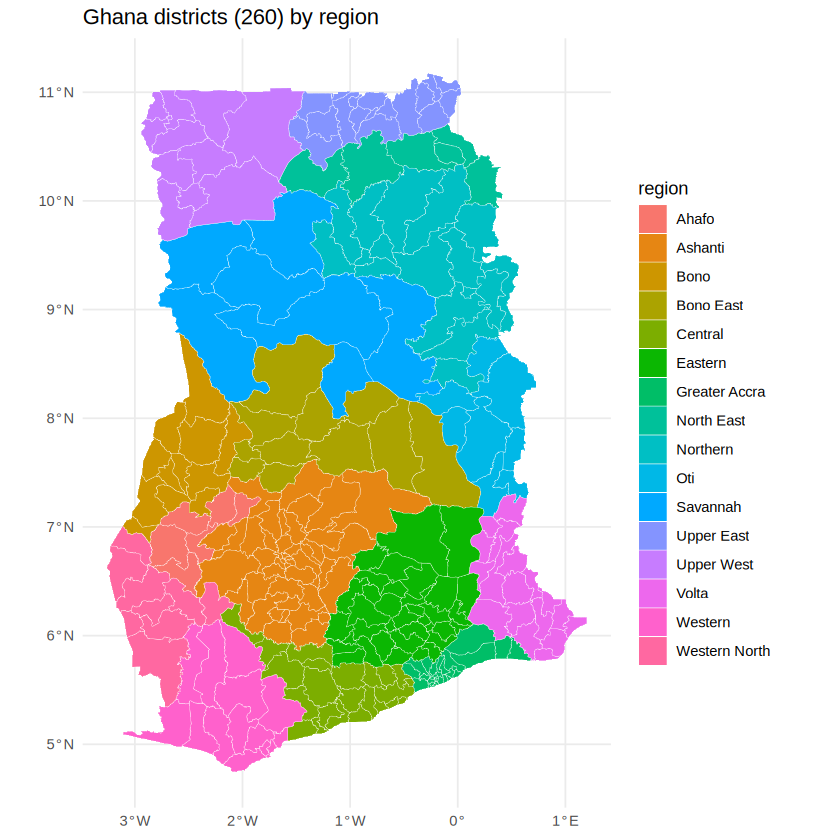

In [ ]:
ggplot(districts) + geom_sf(aes(fill = region), colour = "white", linewidth = 0.1) +
  labs(title = "Ghana districts (260) by region") + theme_minimal()

One rule for the whole module: whenever you measure a distance or an area, first transform the layer to a projected coordinate system in metres. For Ghana we use UTM Zone 30N, EPSG code 32630. In longitude and latitude a distance of 0.01 means different things in different places; in UTM a distance of 1000 always means 1000 metres.

In [ ]:
districts_utm <- st_transform(districts, 32630)

# Topic 1 – Point Pattern Analysis of Geocoded Cases

## 1.4 Step by step in R with Ama's data

Step 1. Read the cases and the boundary, put both in metres, and look.

In [ ]:
cases <- read_csv(file.path(data_dir, "bolga_cases_2024.csv"))
head(cases); nrow(cases)

Rows: 1265 Columns: 5
── Column specification ────────────────────────────────────────────────────────
Delimiter: ","
chr  (2): case_id, age_group
dbl  (2): lon, lat
date (1): date

ℹ Use `spec()` to retrieve the full column specification for this data.
ℹ Specify the column types or set `show_col_types = FALSE` to quiet this message.


case_id,lon,lat,date,age_group
<chr>,<dbl>,<dbl>,<date>,<chr>
BM1106,-0.90168,10.80232,2024-08-23,5-14
BM0105,-0.97625,10.77434,2024-09-28,5-14
BM0312,-0.86833,10.76849,2024-09-18,15+
BM0142,-0.95753,10.83035,2024-06-02,<5
BM0545,-0.86883,10.80226,2024-12-11,15+
BM0770,-0.86061,10.78424,2024-10-16,5-14


[1] 1265

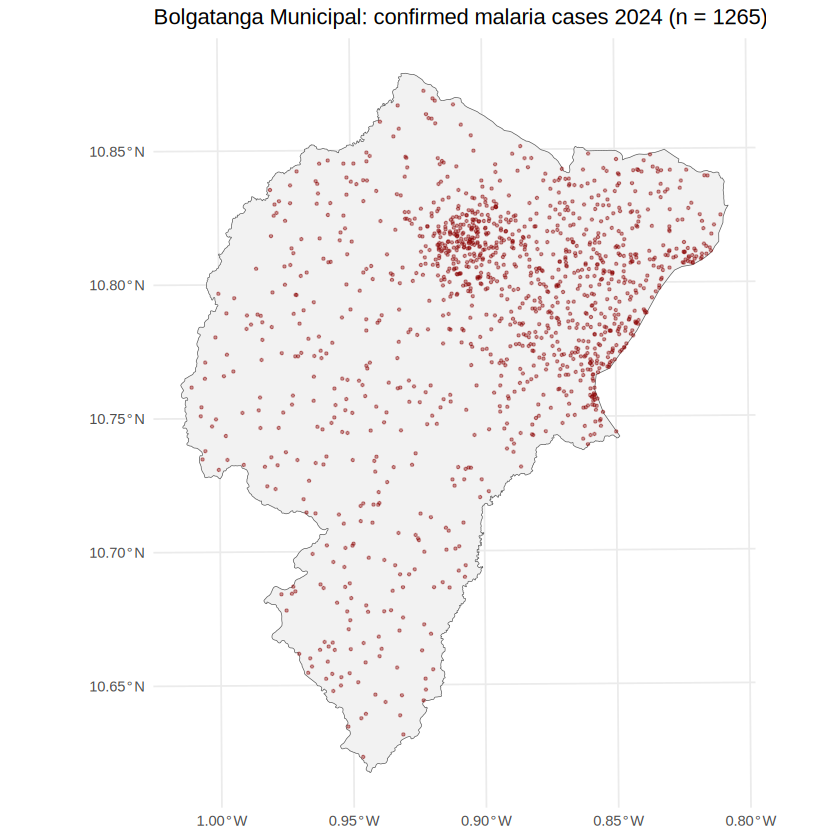

In [ ]:
cases_sf <- st_as_sf(cases, coords = c("lon", "lat"), crs = 4326) |> st_transform(32630)
bolga    <- districts_utm |> filter(adm2_name == "Bolgatanga Municipal")

ggplot() + geom_sf(data = bolga, fill = "grey95") +
  geom_sf(data = cases_sf, size = 0.6, alpha = 0.4, colour = "darkred") +
  labs(title = paste0("Bolgatanga Municipal: confirmed malaria cases 2024 (n = ", nrow(cases), ")")) +
  theme_minimal()

cases_sf <- st_filter(cases_sf, bolga)     # drop any case geocoded outside the district

Step 2. Build the point pattern object. The window is the district polygon; the points are the case coordinates. The geoBoundaries polygon has 3,024 vertices, and every distance calculation in spatstat has to check the boundary, so we simplify it first; this changes nothing visible and makes the later steps about a hundred times faster.

In [ ]:
nrow(st_coordinates(bolga))                          # vertices before simplifying
bolga_simple <- st_simplify(bolga, dTolerance = 50)  # keep detail above 50 m
nrow(st_coordinates(bolga_simple))                   # vertices after

[1] 3024

[1] 350

In [ ]:
win <- as.owin(st_geometry(bolga_simple))
xy  <- st_coordinates(cases_sf)
pp  <- ppp(x = xy[, 1], y = xy[, 2], window = win)
pp                        # number of points and the window
sum(duplicated(pp))       # cases at exactly the same location
pp <- rjitter(pp, radius = 20)   # move each point up to 20 m so that no two coincide

Planar point pattern: 1265 points
window: polygonal boundary
enclosing rectangle: [717115.3, 739760.8] x [1174398.9, 1203340.5] units

[1] 0

The window units are metres because we transformed to UTM. Zero duplicates here because the training data were jittered already; with a real line list you will usually see dozens (several cases at the same compound), and rjitter separates them.

Step 3. Kernel density at three bandwidths. density() returns cases per square metre; multiplying by one million gives cases per square kilometre.

### Visual explainer: From case points to density maps (KDE)

*This visual shows how case locations become a smooth density surface and how bandwidth changes the hotspot map.*

<div style="text-align:center; margin: 12px 0 24px 0;">
  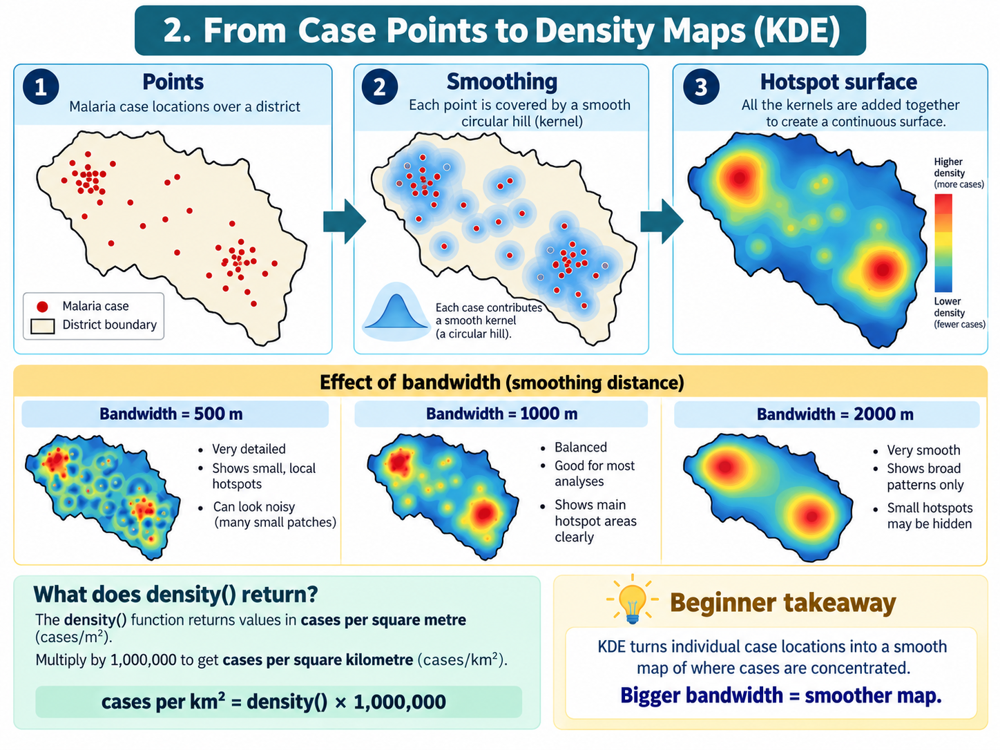
</div>


   Min. 1st Qu.  Median    Mean 3rd Qu.    Max.     NAs 
 0.3669  1.5555  1.9230  3.8669  4.8475 22.1848    8250 

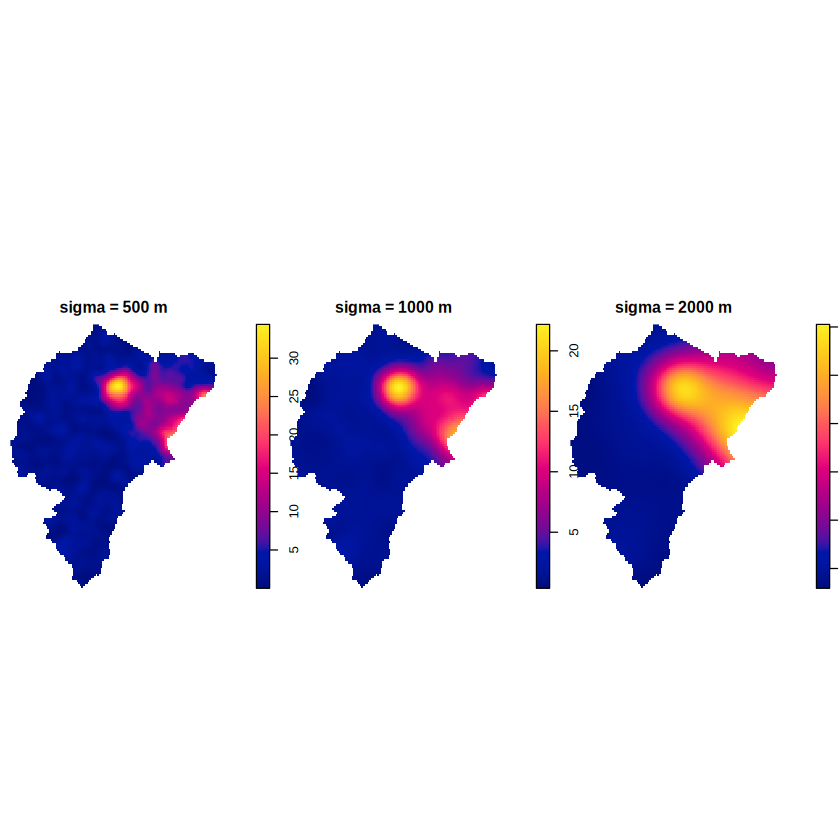

In [ ]:
d500  <- density(pp, sigma = 500)
d1000 <- density(pp, sigma = 1000)
d2000 <- density(pp, sigma = 2000)
par(mfrow = c(1, 3), mar = c(0, 0, 2, 0))
plot(d500  * 1e6, main = "sigma = 500 m")
plot(d1000 * 1e6, main = "sigma = 1000 m")
plot(d2000 * 1e6, main = "sigma = 2000 m")
par(mfrow = c(1, 1))
summary(as.vector(as.matrix(d1000 * 1e6)))     # cases per km2

Step 4. Population control points from the population raster, then the relative-risk surface. The raster has 1 km pixels; we split each into 100 pixels of 100 m so that control points can fall anywhere inside a pixel, and we sample 3,000 points with probability proportional to the number of people in the pixel. Because relrisk() returns the ratio of case density to control density, and we have fewer cases than controls, we divide by the overall case-to-control ratio so that a value of 1 means average risk.

Warning message:
“667 points were rejected as lying outside the specified window”
Warning message:
“data contain duplicated points”


Marked planar point pattern: 3598 points
Multitype, with levels = case, control 
window: polygonal boundary
enclosing rectangle: [717115.3, 739760.8] x [1174398.9, 1203340.5] units
*** 667 illegal points stored in attr(,“rejects”) ***

   Min. 1st Qu.  Median    Mean 3rd Qu.    Max.     NAs 
 0.3985  0.7610  0.8600  1.0363  0.9926  4.1290    8250 

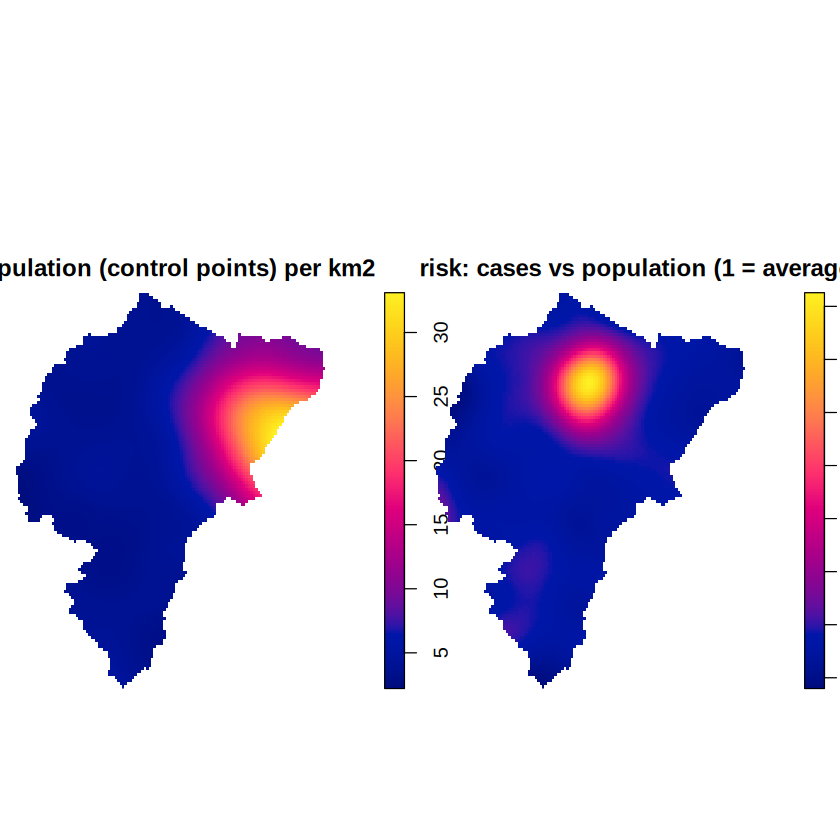

In [ ]:
pop <- rast(file.path(data_dir, "rasters/worldpop_2023.tif")) |>
  project("EPSG:32630") |> crop(vect(bolga_simple)) |> mask(vect(bolga_simple))
pop_fine <- disagg(pop, 10) / 100              # 100 m pixels, people per pixel

set.seed(1)
cells <- which(!is.na(values(pop_fine)))
sel   <- sample(cells, 3000, replace = TRUE, prob = values(pop_fine)[cells])
ctrl  <- as.data.frame(xyFromCell(pop_fine, sel))

all_pts <- bind_rows(tibble(x = xy[, 1], y = xy[, 2], type = "case"),
                     tibble(x = ctrl$x,  y = ctrl$y,  type = "control"))
pp2 <- ppp(all_pts$x, all_pts$y, window = win, marks = factor(all_pts$type))
pp2 <- rjitter(pp2, radius = 20)

rr <- relrisk(pp2, sigma = 1500, relative = TRUE, control = "control")
rr <- rr / (sum(marks(pp2) == "case") / sum(marks(pp2) == "control"))   # 1 = average risk
pp2
summary(as.vector(as.matrix(rr)))

par(mfrow = c(1, 2), mar = c(0, 0, 2, 0))
plot(density(pp2[marks(pp2) == "control"], sigma = 1500) * 1e6, main = "Population (control points) per km2")
plot(rr, main = "Relative risk: cases vs population (1 = average)")
par(mfrow = c(1, 1))

The message about 622 illegal points is harmless: some control points fell just outside the simplified boundary and were dropped.

Step 5. Is the clustering more than chance? The L function with a simulation envelope. rmax = 3000 limits the calculation to distances up to 3 km, which is all we need and keeps it fast.

Generating 99 simulated realisations of CSR  ...
1, 2, 3, 4, 5, 6, 7, 8, 9, 10, 11, 12, 13, 14, 15, 16, 17, 18, 19, 20,
21, 22, 23, 24, 25, 26, 27, 28, 29, 30, 31, 32, 33, 34, 35, 36, 37, 38, 39, 40,
41, 42, 43, 44, 45, 46, 47, 48, 49, 50, 51, 52, 53, 54, 55, 56, 57, 58, 59, 60,
61, 62, 63, 64, 65, 66, 67, 68, 69, 70, 71, 72, 73, 74, 75, 76, 77, 78, 79, 80,
81, 82, 83, 84, 85, 86, 87, 88, 89, 90, 91, 92, 93, 94, 95, 96, 97, 98, 
99.

Done.


r,obs,theo,lo,hi
<dbl>,<dbl>,<dbl>,<dbl>,<dbl>
0.000000,0.00000,0.000000,0.00000,0.00000
5.859375,16.10137,5.859375,0.00000,16.34699
11.718750,19.72007,11.718750,0.00000,23.28641
17.578125,32.20274,17.578125,0.00000,28.15558
23.437500,41.05060,23.437500,0.00000,34.87321
29.296875,54.60240,29.296875,11.22559,39.29055
35.156250,64.40548,35.156250,15.87539,44.79758
41.015625,74.65898,41.015625,22.84303,52.23898
46.875000,82.88687,46.875000,25.53929,60.69621


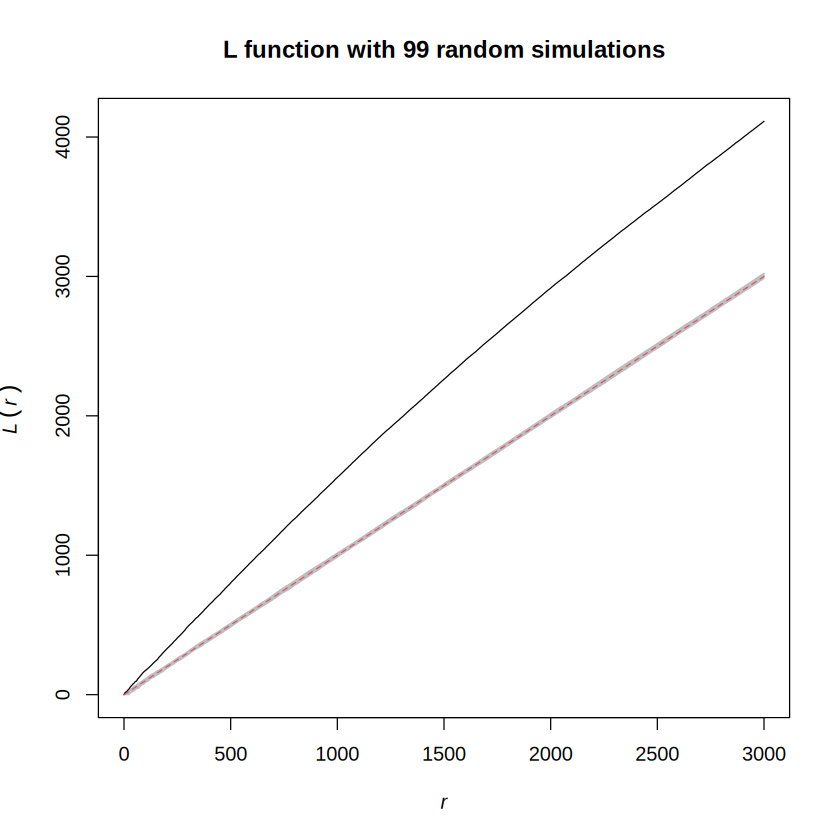

In [ ]:
Lenv <- envelope(pp, Lest, nsim = 99, correction = "Ripley", rmax = 3000)
Lenv
plot(Lenv, main = "L function with 99 random simulations", legend = FALSE)

Step 6. Are nearby cases also close in time? The Knox test. eps.t = 14 means within 14 days; eps.s = 500 means within 500 metres. Ama chose 14 days because it is roughly one incubation period plus reporting delay, and 500 metres because it is about the flight range of the mosquito. You should always be able to say why you chose these numbers.

In [ ]:
day <- as.numeric(as.Date(cases_sf$date))
kn  <- knox(dt = dist(day), ds = dist(xy), eps.t = 14, eps.s = 500,
            simulate.p.value = TRUE, B = 999)
kn

.......................................................................................................................................................................................................................................................................................................................................................................................................................................................................................................................................................................................................................................................................................................................................................................................................................................................................................................................................................................................................................................



	Knox test with simulated p-value

data:  dt = dist(day) and ds = dist(xy)
number of close pairs = 1719, B = 999, p-value = 0.001
alternative hypothesis: true number is greater than 671.531

contingency table:
       ds
dt      <= 500  > 500
  <= 14   1719 110928
   > 14   3047 683786


## 1.8 Trial test 1

Answer the trial test on paper (manual section 1.8). Answers are at the end of the manual.

# Topic 2 – Spatial Autocorrelation and Hotspot Mapping of Area Data

## 2.4 Step by step in R with Ama's data

Step 1. Join cases, deaths and population to the district map and compute the raw rates. anti_join() lists any district codes in the table that are not on the map; it must return zero rows.

Rows: 260 Columns: 4
── Column specification ────────────────────────────────────────────────────────
Delimiter: ","
chr (1): adm2_code
dbl (3): cases, deaths, population

ℹ Use `spec()` to retrieve the full column specification for this data.
ℹ Specify the column types or set `show_col_types = FALSE` to quiet this message.


adm2_code,cases,deaths,population
<chr>,<dbl>,<dbl>,<dbl>
GH001,21921,3,134392
GH002,13232,6,86695
GH003,8075,8,84450
GH004,6978,5,54748
GH005,14650,5,73684
GH006,2953,0,44833


   Min. 1st Qu.  Median    Mean 3rd Qu.    Max. 
  0.000   1.000   3.000   5.442   6.250  47.000 

adm2_code,cases,deaths,population
<chr>,<dbl>,<dbl>,<dbl>


   Min. 1st Qu.  Median    Mean 3rd Qu.    Max. 
  13.76   97.47  137.33  141.03  167.32  352.08 

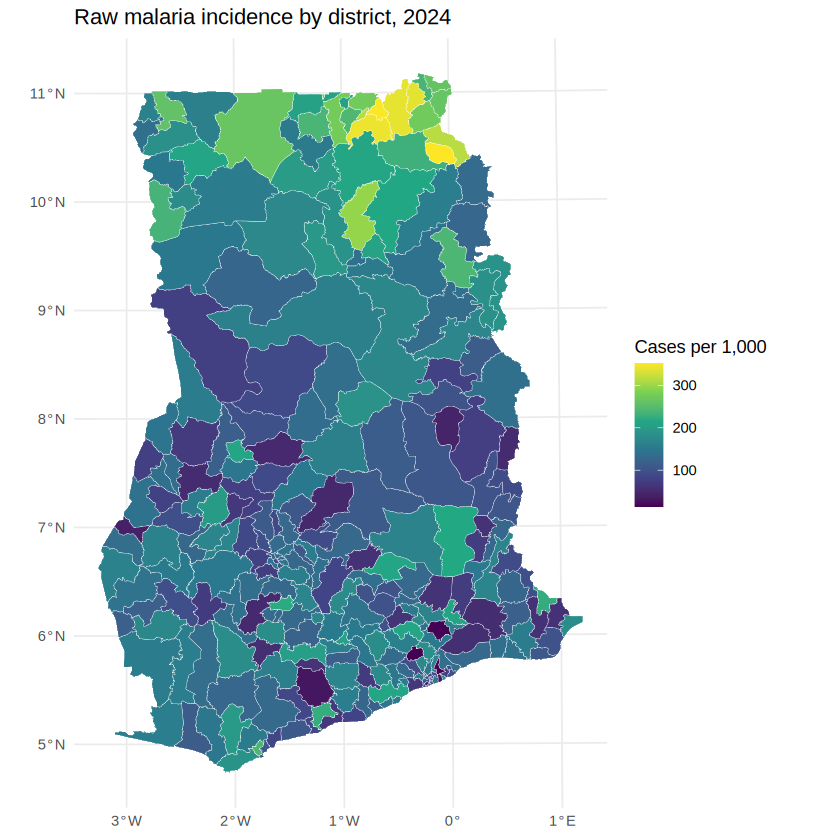

In [ ]:
mal <- read_csv(file.path(data_dir, "malaria_district_2024.csv"))
head(mal); summary(mal$deaths)

map_df <- districts_utm |>
  left_join(mal, by = "adm2_code") |>
  mutate(rate_raw  = cases  / population * 1000,     # incidence per 1,000
         death_raw = deaths / population * 1e5)      # deaths per 100,000

anti_join(mal, st_drop_geometry(districts_utm), by = "adm2_code")   # must be 0 rows
summary(map_df$rate_raw)

ggplot(map_df) + geom_sf(aes(fill = rate_raw), colour = "white", linewidth = 0.1) +
  scale_fill_viridis_c("Cases per 1,000") + labs(title = "Raw malaria incidence by district, 2024") + theme_minimal()

Step 2. Neighbours and weights. Build queen contiguity first, then a second definition to compare.

### Visual explainer: Spatial data and coordinate systems

*This visual introduces sf objects, coordinate systems, and why projected CRS in metres is needed before measuring distance, area, neighbours or buffers.*

<div style="text-align:center; margin: 12px 0 24px 0;">
  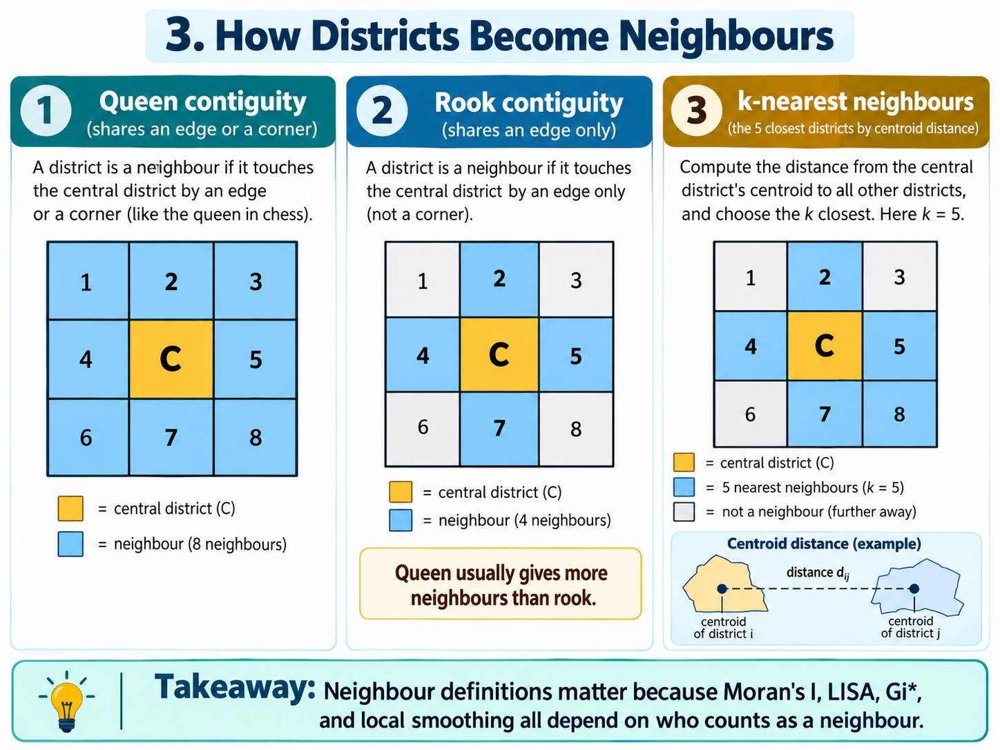
</div>


### Visual explainer: How districts become neighbours

*This visual compares queen contiguity, rook contiguity and k-nearest neighbours.*

<div style="text-align:center; margin: 12px 0 24px 0;">
  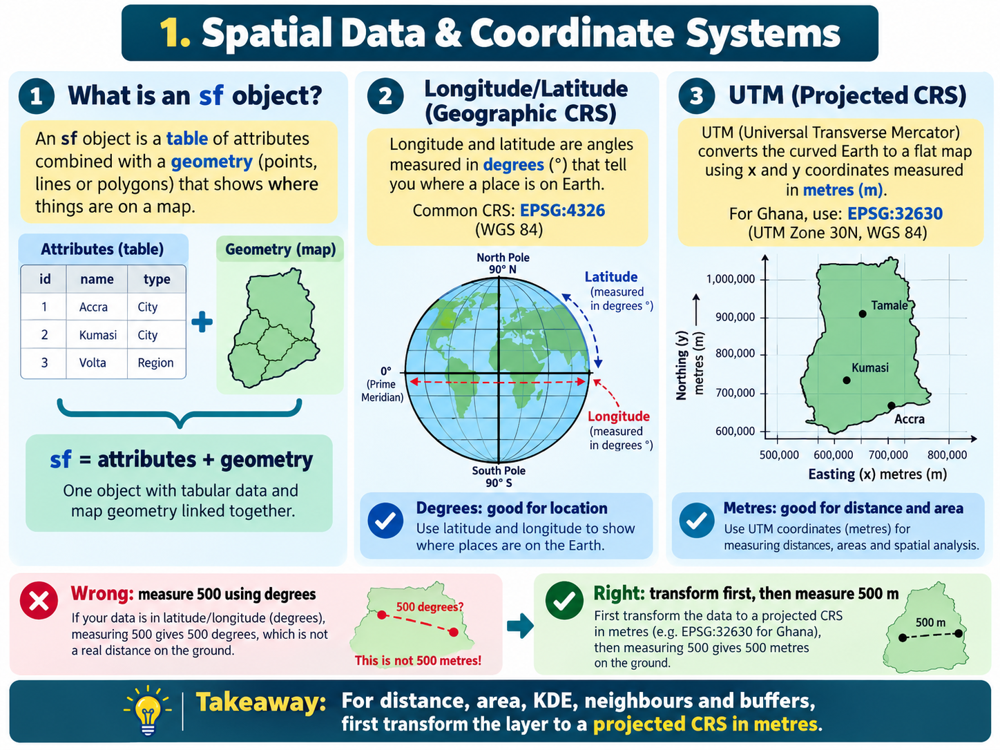
</div>


Neighbour list object:
Number of regions: 260 
Number of nonzero links: 1418 
Percentage nonzero weights: 2.097633 
Average number of links: 5.453846 

Neighbour list object:
Number of regions: 260 
Number of nonzero links: 1300 
Percentage nonzero weights: 1.923077 
Average number of links: 5 
Non-symmetric neighbours list

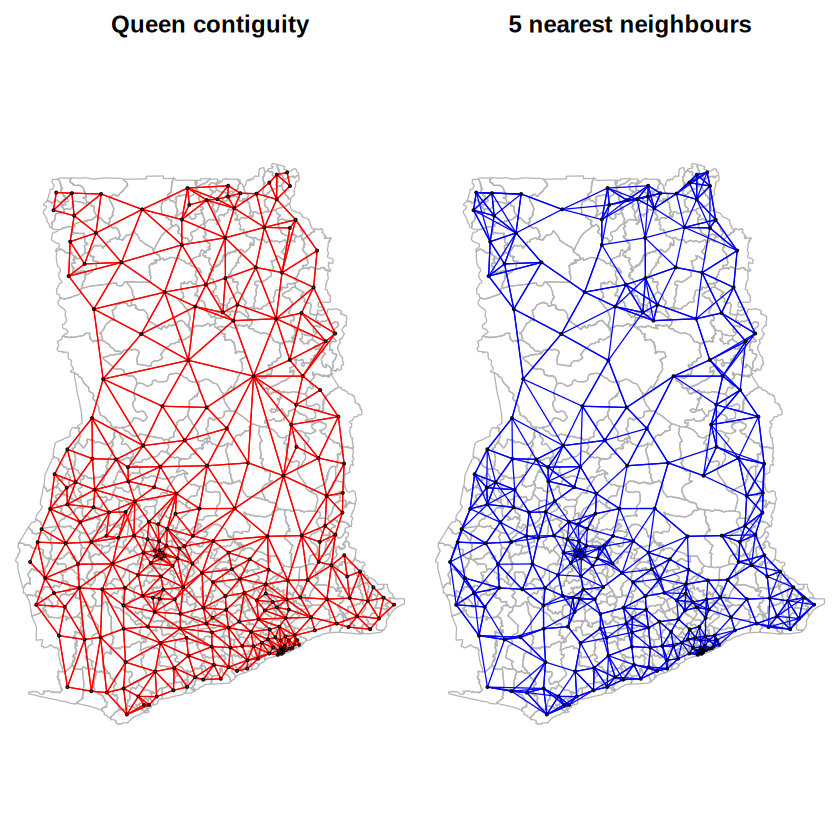

In [ ]:
nb_q <- poly2nb(map_df, queen = TRUE)
nb_q
lw_q <- nb2listw(nb_q, style = "W", zero.policy = TRUE)

coords <- st_coordinates(st_centroid(st_geometry(map_df)))
nb_k   <- knn2nb(knearneigh(coords, k = 5))
nb_k
lw_k   <- nb2listw(nb_k, style = "W")

par(mfrow = c(1, 2), mar = c(0, 0, 2, 0))...$0
plot(st_geometry(map_df), border = "grey70", main = "Queen contiguity"); plot(nb_q, coords, add = TRUE, col = "red", cex = 0.3)
plot(st_geometry(map_df), border = "grey70", main = "5 nearest neighbours"); plot(nb_k, coords, add = TRUE, col = "blue", cex = 0.3)
par(mfrow = c(1, 1))

If poly2nb reports a district with zero links, it is an island in the data. zero.policy = TRUE lets the analysis continue; the k-nearest definition gives that district neighbours anyway. Here every district has at least one neighbour.

Step 3. Empirical Bayes smoothing, global and local. We show it on malaria deaths, where counts are small (median 3 per district) and the effect is easy to see, and then on cases, where counts are large and the rate barely changes.

### Visual explainer: Why we smooth disease rates

*This visual explains unstable raw rates, and the difference between global and local empirical Bayes smoothing.*

<div style="text-align:center; margin: 12px 0 24px 0;">
  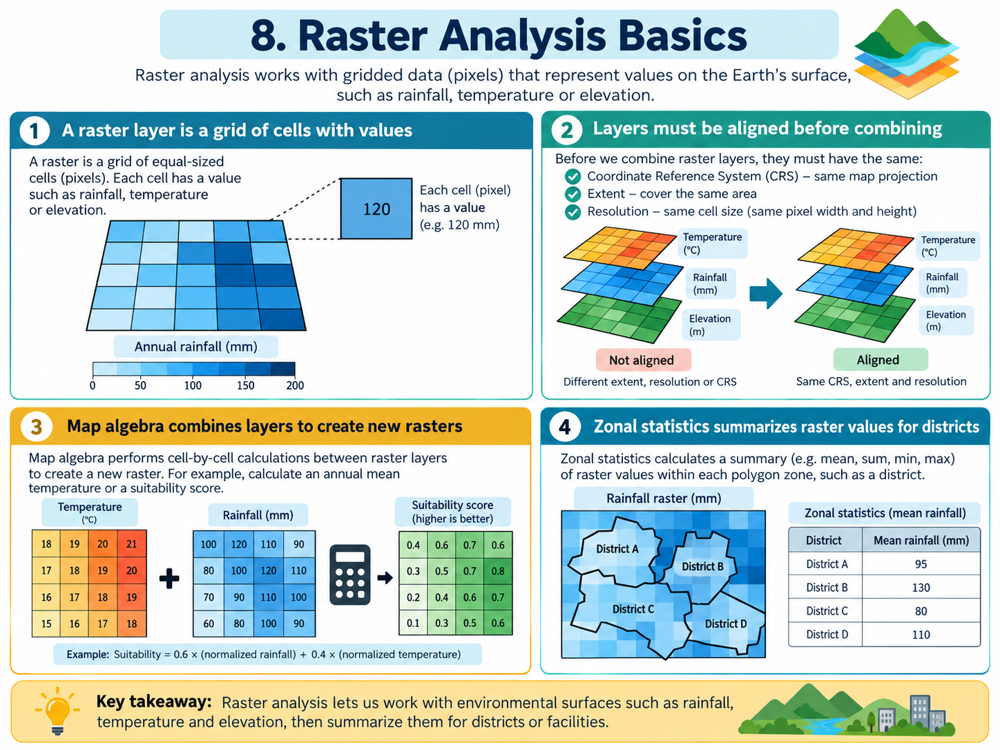
</div>


In [ ]:
eb_g <- EBest(map_df$deaths, map_df$population)          # global: toward the national rate
eb_l <- EBlocal(map_df$deaths, map_df$population, nb_q)  # local: toward the neighbours
map_df <- map_df |>
  mutate(death_eb_global = eb_g$estmm * 1e5,
         death_eb_local  = eb_l$est   * 1e5)

eb_c <- EBlocal(map_df$cases, map_df$population, nb_q)   # the same for cases
map_df <- map_df |> mutate(rate_eb_local = eb_c$est * 1000)

map_df |> st_drop_geometry() |>
  select(adm2_name, population, deaths, death_raw, death_eb_global, death_eb_local) |>
  arrange(desc(death_raw)) |> head(10)
map_df |> st_drop_geometry() |>
  select(adm2_name, population, cases, rate_raw, rate_eb_local) |>
  arrange(population) |> head(5)

,adm2_name,population,deaths,death_raw,death_eb_global,death_eb_local
,<chr>,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>
1,Yunyoo-nasuan,41888,11,26.26050,11.774990,17.896111
2,Suhum Municipal,41960,7,16.68255,8.945453,9.810904
3,Abura-asebu-kwamankese,45065,7,15.53312,8.753594,12.254017
4,Karaga,272654,41,15.03737,12.534290,13.413742
5,Nandom,33402,5,14.96916,8.018047,8.805143
6,Mpohor,66926,10,14.94188,9.405557,9.939920
7,Binduri,35450,5,14.10437,7.896550,9.196812
8,Sekyere Kumawu,64018,9,14.05855,8.961830,8.860799
9,Wa West,130243,18,13.82032,10.294749,10.661538


,adm2_name,population,cases,rate_raw,rate_eb_local
,<chr>,<dbl>,<dbl>,<dbl>,<dbl>
1,Assin Fosu,25945,1590,61.28348,61.35742
2,La-nkwantanang-madina,26179,4268,163.03144,162.91050
3,Ketu South,26538,4749,178.95094,178.82154
4,Ekumfi,26803,2150,80.21490,80.27693
5,Shama,27292,2276,83.39440,83.75606


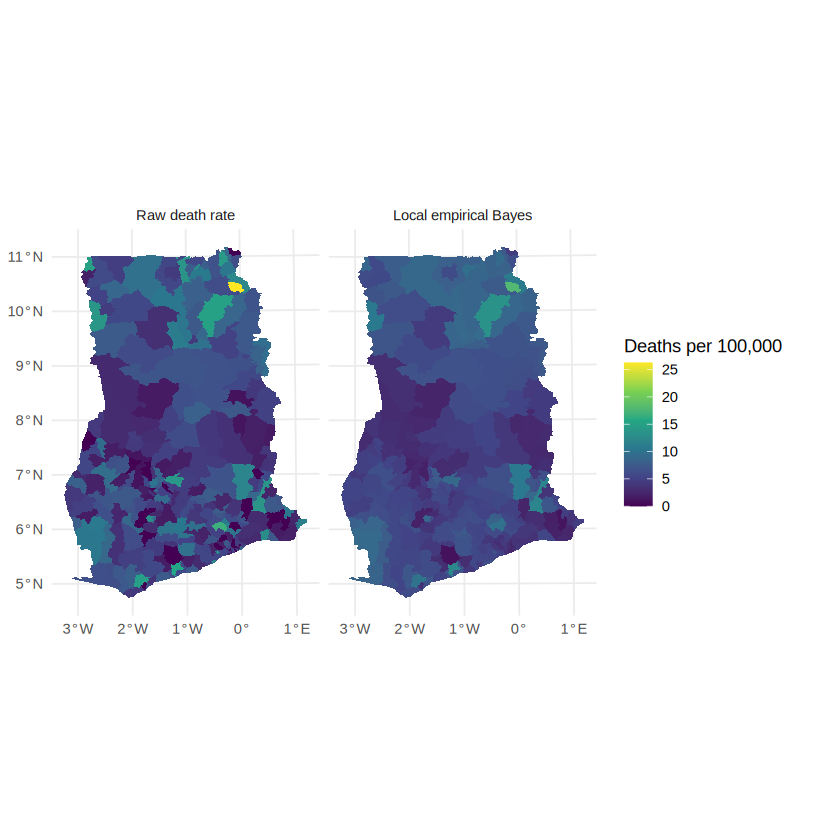

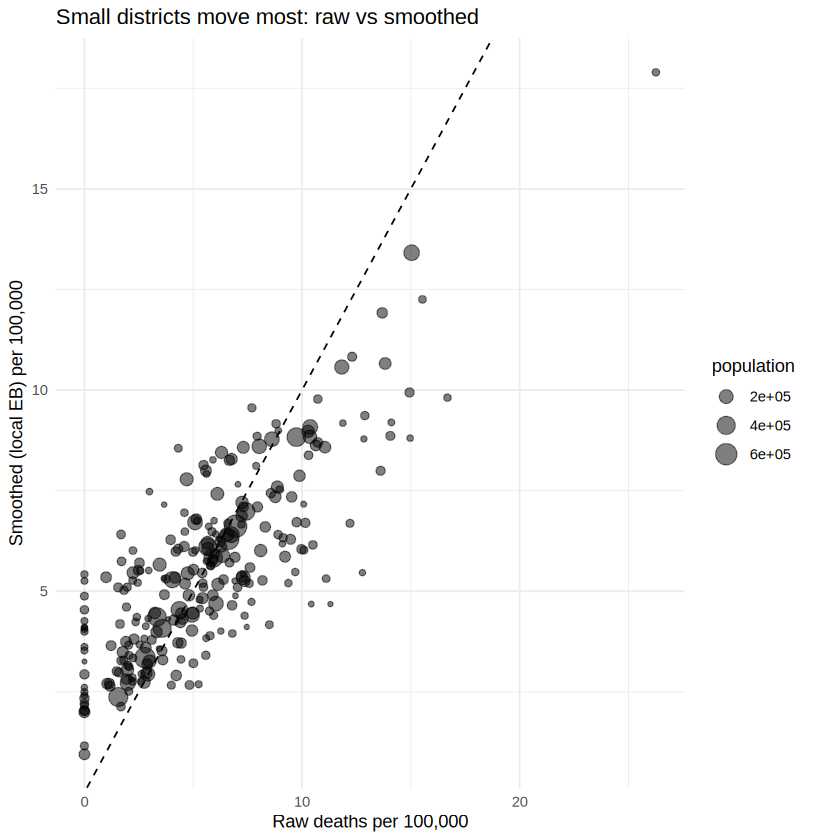

In [ ]:
long <- map_df |> select(death_raw, death_eb_local) |>
  pivot_longer(c(death_raw, death_eb_local), names_to = "which", values_to = "rate") |>
  mutate(which = factor(which, c("death_raw", "death_eb_local"), c("Raw death rate", "Local empirical Bayes")))
ggplot(long) + geom_sf(aes(fill = rate), colour = NA) + facet_wrap(~which) +
  scale_fill_viridis_c("Deaths per 100,000") + theme_minimal()

ggplot(st_drop_geometry(map_df), aes(death_raw, death_eb_local, size = population)) +
  geom_abline(linetype = 2) + geom_point(alpha = 0.5) +
  labs(x = "Raw deaths per 100,000", y = "Smoothed (local EB) per 100,000",
       title = "Small districts move most: raw vs smoothed") + theme_minimal()

Read the table: Yunyoo-Nasuan, with 11 deaths in 41,888 people, has a raw rate of 26 per 100,000 and a smoothed rate of 18; Karaga, with 41 deaths in 272,654 people, moves only from 15.0 to 13.4. For cases the five smallest districts move by 0.1 per 1,000 or less, because thousands of cases are strong evidence.

Step 4. Global Moran's I on smoothed incidence, under both neighbour definitions, plus the permutation version.

### Visual explainer: Moran’s I, LISA and Gi*

*This visual contrasts global autocorrelation, local clusters/outliers and hot-spot analysis.*

<div style="text-align:center; margin: 12px 0 24px 0;">
  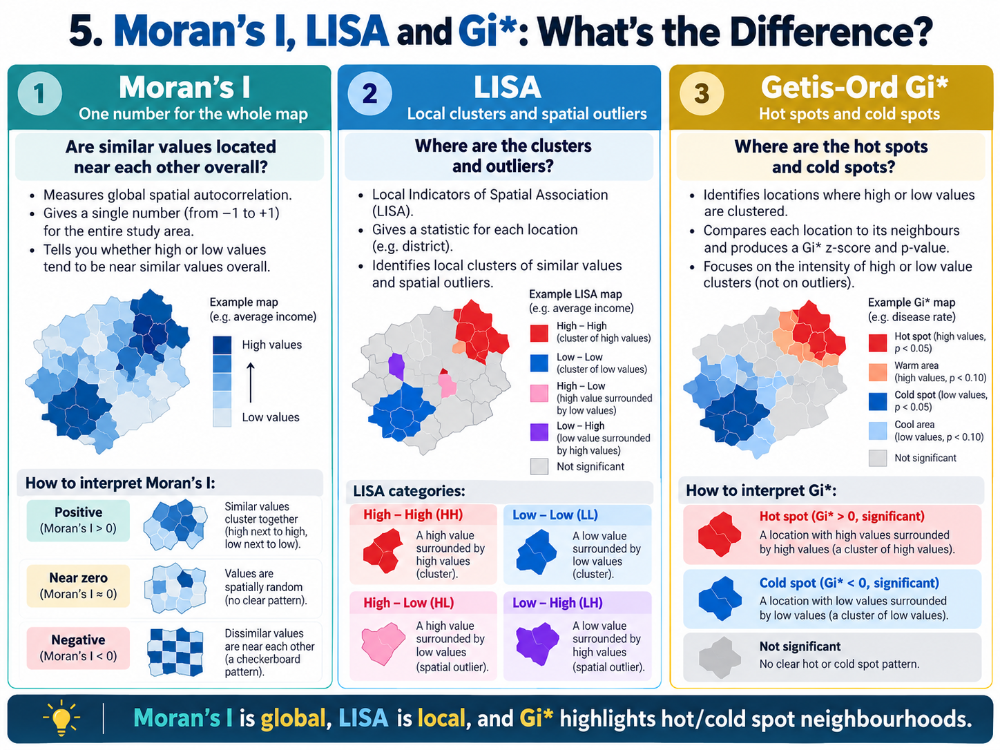
</div>



	Moran I test under randomisation

data:  map_df$rate_eb_local  
weights: lw_q    

Moran I statistic standard deviate = 11.179, p-value < 2.2e-16
alternative hypothesis: greater
sample estimates:
Moran I statistic       Expectation          Variance 
      0.422678325      -0.003861004       0.001455904 



	Moran I test under randomisation

data:  map_df$rate_eb_local  
weights: lw_k    

Moran I statistic standard deviate = 13.47, p-value < 2.2e-16
alternative hypothesis: greater
sample estimates:
Moran I statistic       Expectation          Variance 
      0.489171428      -0.003861004       0.001339669 



	Monte-Carlo simulation of Moran I

data:  map_df$rate_eb_local 
weights: lw_q  
number of simulations + 1: 1000 

statistic = 0.42268, observed rank = 1000, p-value = 0.001
alternative hypothesis: greater


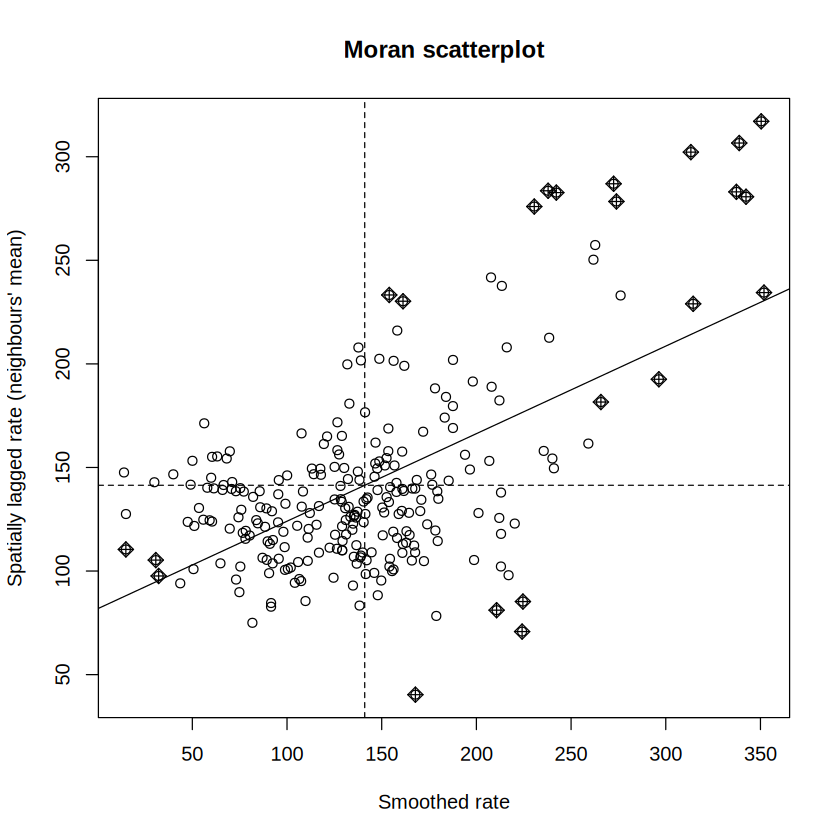

In [ ]:
moran.test(map_df$rate_eb_local, lw_q, zero.policy = TRUE)
moran.test(map_df$rate_eb_local, lw_k)
moran.mc(map_df$rate_eb_local, lw_q, nsim = 999, zero.policy = TRUE)

moran.plot(map_df$rate_eb_local, lw_q, zero.policy = TRUE, labels = FALSE,
           xlab = "Smoothed rate", ylab = "Spatially lagged rate (neighbours' mean)",
           main = "Moran scatterplot")

Step 5. Local Moran (LISA) cluster map.

,Ii,E.Ii,Var.Ii,Z.Ii,Pr(z != E(Ii))
1,-0.12393042,-0.0004838805,0.017546240,-0.9319377,0.3513687
2,-0.01595773,-0.0001332019,0.006818202,-0.1916442,0.8480209
3,-0.03369166,-0.0020485382,0.086871314,-0.1073597,0.9145037
4,-0.05315588,-0.0001822235,0.006609693,-0.6515824,0.5146706
5,-0.53132253,-0.0033170420,0.119940026,-1.5246016,0.1273585



      High-High        High-Low        Low-High         Low-Low Not significant 
             26               5               1               4             224 

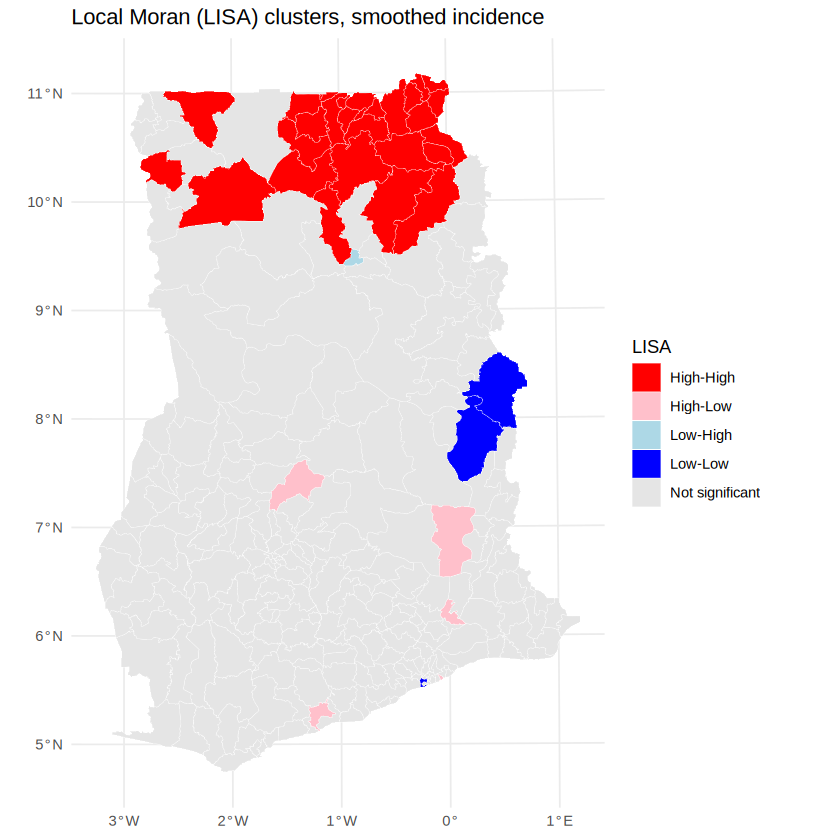

In [ ]:
lisa <- localmoran(map_df$rate_eb_local, lw_q, zero.policy = TRUE)
head(lisa, 5)
map_df <- map_df |>
  mutate(lisa_p    = lisa[, "Pr(z != E(Ii))"],
         lisa_type = as.character(attr(lisa, "quadr")$mean),
         lisa_lab  = if_else(lisa_p < 0.05, lisa_type, "Not significant"))
table(map_df$lisa_lab)

ggplot(map_df) + geom_sf(aes(fill = lisa_lab), colour = "white", linewidth = 0.1) +
  scale_fill_manual("LISA", values = c("High-High" = "red", "Low-Low" = "blue",
                                       "High-Low" = "pink", "Low-High" = "lightblue",
                                       "Not significant" = "grey90")) +
  labs(title = "Local Moran (LISA) clusters, smoothed incidence") + theme_minimal()

Step 6. Getis-Ord Gi* hot and cold spots. Gi* includes the district itself in its own neighbourhood, so we add self to the neighbour list.

    Min.  1st Qu.   Median     Mean  3rd Qu.     Max. 
-2.89470 -1.10742 -0.48668 -0.01384  0.40207  6.78784 


      Cold spot        Hot spot Not significant 
              8              29             223 

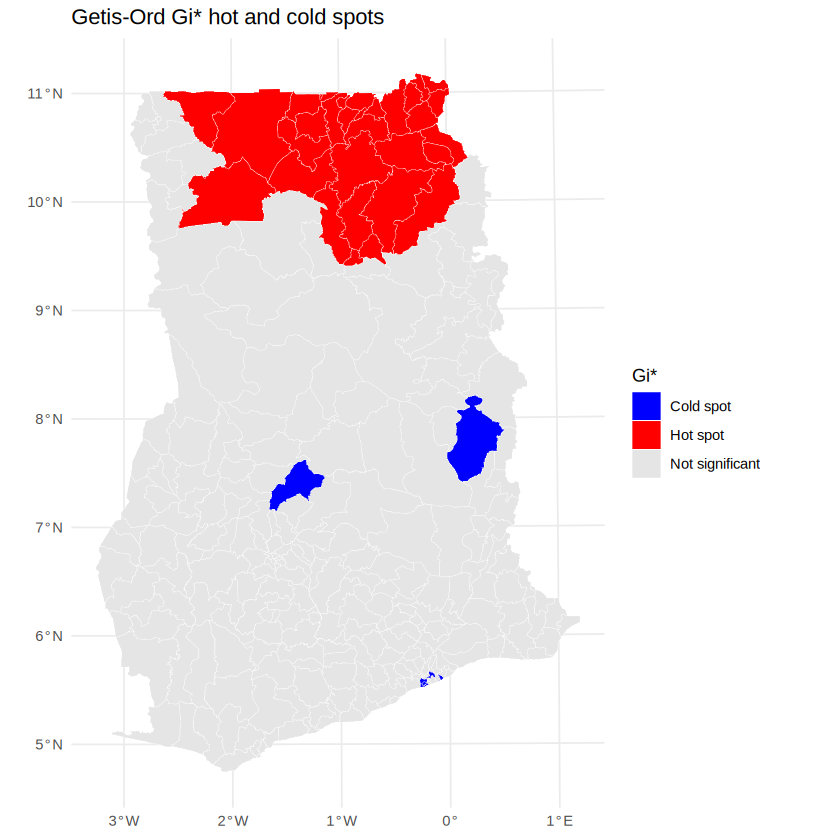

In [ ]:
nb_self <- include.self(nb_q)
lw_self <- nb2listw(nb_self, style = "W", zero.policy = TRUE)
gi <- localG(map_df$rate_eb_local, lw_self, zero.policy = TRUE)
map_df <- map_df |>
  mutate(gi_z   = as.numeric(gi),
         gi_lab = case_when(gi_z >  1.96 ~ "Hot spot",
                            gi_z < -1.96 ~ "Cold spot",
                            TRUE ~ "Not significant"))
summary(map_df$gi_z); table(map_df$gi_lab)

ggplot(map_df) + geom_sf(aes(fill = gi_lab), colour = "white", linewidth = 0.1) +
  scale_fill_manual("Gi*", values = c("Hot spot" = "red", "Cold spot" = "blue", "Not significant" = "grey90")) +
  labs(title = "Getis-Ord Gi* hot and cold spots") + theme_minimal()

Step 7. Kulldorff's spatial scan statistic. geo holds district centre coordinates in kilometres. pop.upper.bound = 0.2 means the circle may not contain more than 20 percent of the national population; this stops the method from calling half the country a cluster.

[1] 197 199 198 205 207 203 195 200 204 161 196 159 202 201 194 208 206 160 162
[20] 157 164 173 215 166

[1] 639602

[1] 369347.7

[1] 1.731707

[1] 0.001

[1] "Bunkpurugu Nakpanduri"   "East Mamprusi"          
 [3] "Mamprugu Moagduri"       "West Mamprusi Municipal"
 [5] "Yunyoo-nasuan"           "Karaga"                 
 [7] "Kumbungu"                "Savelugu"               
 [9] "Bawku Municipal"         "Bawku West"             
[11] "Binduri"                 "Bolga East"             
[13] "Bolgatanga Municipal"    "Bongo"                  
[15] "Builsa North"            "Builsa South"           
[17] "Garu"                    "Kasena Nankana East"    
[19] "Kasena Nankana West"     "Nabdam"                 
[21] "Pusiga"                  "Talensi"                
[23] "Tempane"                 "Sissala East"

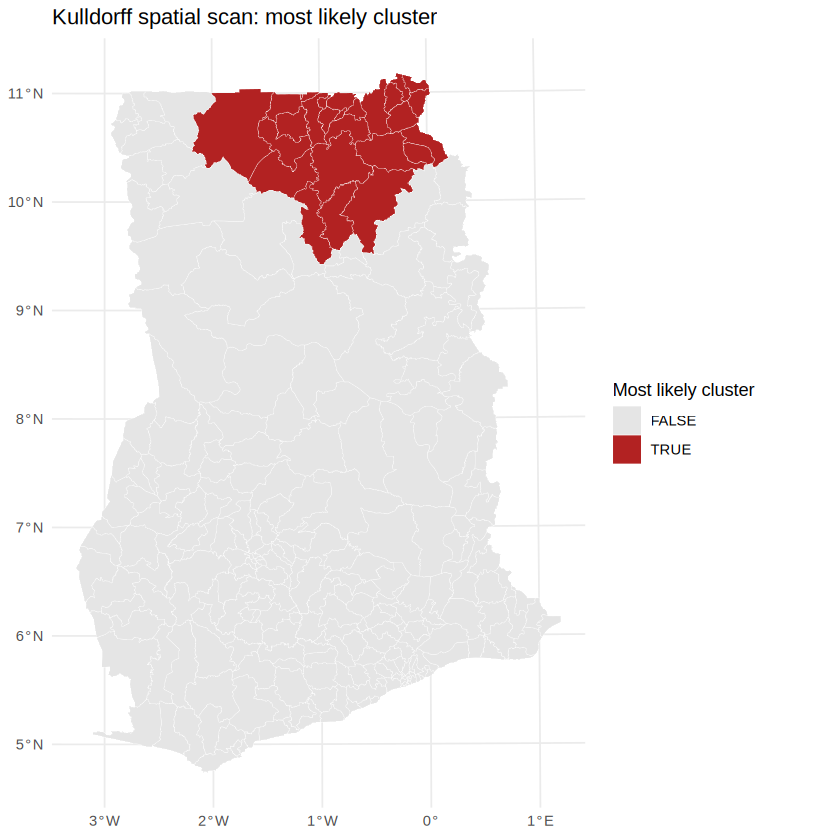

In [ ]:
geo <- st_coordinates(st_centroid(st_geometry(map_df))) / 1000     # kilometres
ks  <- kulldorff(geo = geo, cases = map_df$cases, population = map_df$population,
                 expected.cases = NULL, pop.upper.bound = 0.2,
                 n.simulations = 999, alpha.level = 0.05, plot = FALSE)

ks$most.likely.cluster$location.IDs.included   # row numbers of districts in the cluster
ks$most.likely.cluster$number.of.cases
ks$most.likely.cluster$expected.cases
ks$most.likely.cluster$SMR                      # observed / expected inside the cluster
ks$most.likely.cluster$p.value

map_df <- map_df |>
  mutate(in_cluster = row_number() %in% ks$most.likely.cluster$location.IDs.included)
map_df$adm2_name[map_df$in_cluster]

ggplot(map_df) + geom_sf(aes(fill = in_cluster), colour = "white", linewidth = 0.1) +
  scale_fill_manual("Most likely cluster", values = c("TRUE" = "firebrick", "FALSE" = "grey90")) +
  labs(title = "Kulldorff spatial scan: most likely cluster") + theme_minimal()

## 2.8 Trial test 2

Answer the trial test on paper (manual section 2.8). Answers are at the end of the manual.

# Topic 3 – Spatial Interpolation and Geostatistics

## 3.4 Step by step in R with Ama's data

Step 1. Read the survey clusters, compute prevalence, project to metres, and make the Upper East boundary and a prediction grid of points every 2 km.

Rows: 60 Columns: 5
── Column specification ────────────────────────────────────────────────────────
Delimiter: ","
chr (1): cluster_id
dbl (4): lon, lat, tested, positive

ℹ Use `spec()` to retrieve the full column specification for this data.
ℹ Specify the column types or set `show_col_types = FALSE` to quiet this message.


cluster_id,lon,lat,tested,positive,prev
<chr>,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>
UE01,-0.36532,10.90585,120,50,0.41666667
UE02,-0.72295,10.90393,118,12,0.10169492
UE03,-1.30421,10.46332,102,12,0.11764706
UE04,-0.71900,10.99607,91,6,0.06593407
UE05,-0.64562,10.93565,116,9,0.07758621
UE06,-0.26833,10.91442,113,54,0.47787611


   Min. 1st Qu.  Median    Mean 3rd Qu.    Max. 
0.06593 0.13742 0.21446 0.21627 0.26833 0.47788 

[1] 2156

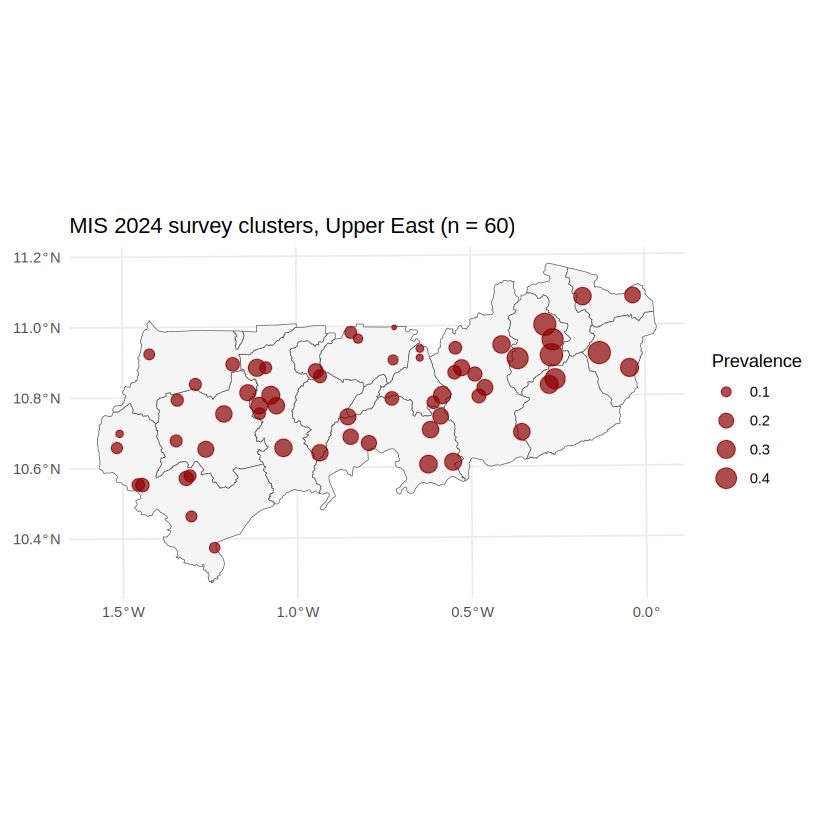

In [ ]:
mis <- read_csv(file.path(data_dir, "mis_clusters_2024.csv")) |>
  mutate(prev = positive / tested)
head(mis); summary(mis$prev)
mis_sf <- st_as_sf(mis, coords = c("lon", "lat"), crs = 4326) |> st_transform(32630)

ue <- districts_utm |> filter(region == "Upper East") |> st_union() |> st_as_sf()
grid <- st_make_grid(ue, cellsize = 2000, what = "centers") |> st_as_sf() |> st_filter(ue)
nrow(grid)

ggplot() + geom_sf(data = districts_utm |> filter(region == "Upper East"), fill = "grey96") +
  geom_sf(data = mis_sf, aes(size = prev), colour = "darkred", alpha = 0.7) +
  scale_size("Prevalence", range = c(1, 6)) +
  labs(title = "MIS 2024 survey clusters, Upper East (n = 60)") + theme_minimal()

Step 2. Inverse-distance weighting.

### Visual explainer: IDW vs kriging

*This visual compares inverse distance weighting and ordinary kriging, including the role of the variogram.*

<div style="text-align:center; margin: 12px 0 24px 0;">
  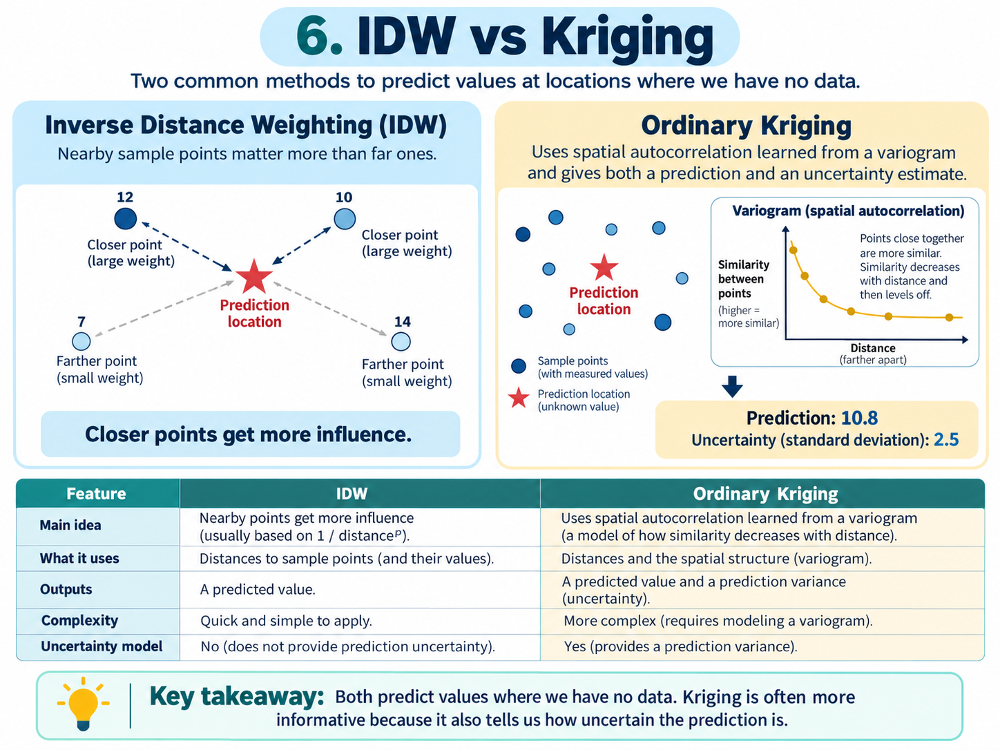
</div>


Registered S3 method overwritten by 'stars':
  method                  from
  st_interpolate_aw.stars sf  



[inverse distance weighted interpolation]


ERROR while rich displaying an object: Error in loadNamespace(x): there is no package called ‘geojsonio’

Traceback:
1. sapply(x, f, simplify = simplify)
2. lapply(X = X, FUN = FUN, ...)
3. FUN(X[[i]], ...)
4. tryCatch(withCallingHandlers({
 .     if (!mime %in% names(repr::mime2repr)) 
 .         stop("No repr_* for mimetype ", mime, " in repr::mime2repr")
 .     rpr <- repr::mime2repr[[mime]](obj)
 .     if (is.null(rpr)) 
 .         return(NULL)
 .     prepare_content(is.raw(rpr), rpr)
 . }, error = error_handler), error = outer_handler)
5. tryCatchList(expr, classes, parentenv, handlers)
6. tryCatchOne(expr, names, parentenv, handlers[[1L]])
7. doTryCatch(return(expr), name, parentenv, handler)
8. withCallingHandlers({
 .     if (!mime %in% names(repr::mime2repr)) 
 .         stop("No repr_* for mimetype ", mime, " in repr::mime2repr")
 .     rpr <- repr::mime2repr[[mime]](obj)
 .     if (is.null(rpr)) 
 .         return(NULL)
 .     prepare_content(is.raw(rpr), rpr)
 . }, error = 

,var1.pred,var1.var,geometry
,<dbl>,<dbl>,<POINT [m]>
1,0.1474597,NA,POINT (691027.3 1139298)
2,0.1472549,NA,POINT (693027.3 1139298)
3,0.1389023,NA,POINT (691027.3 1141298)
4,0.1379134,NA,POINT (693027.3 1141298)
5,0.1405016,NA,POINT (695027.3 1141298)
6,0.1479635,NA,POINT (685027.3 1143298)


   Min. 1st Qu.  Median    Mean 3rd Qu.    Max. 
0.07468 0.16991 0.21210 0.22391 0.26178 0.47133 

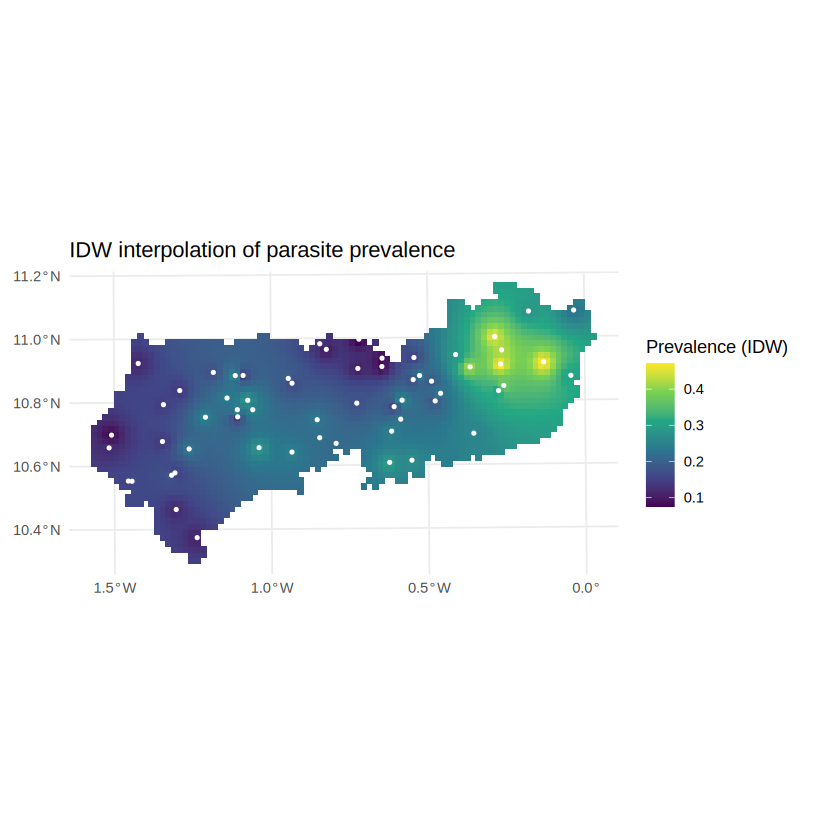

In [ ]:
idw_out <- idw(prev ~ 1, locations = mis_sf, newdata = grid, idp = 2)
head(idw_out); summary(idw_out$var1.pred)

ggplot(idw_out) + geom_sf(aes(colour = var1.pred), size = 1.6, shape = 15) +
  scale_colour_viridis_c("Prevalence (IDW)") + geom_sf(data = mis_sf, colour = "white", size = 0.8) +
  labs(title = "IDW interpolation of parasite prevalence") + theme_minimal()

Step 3. The variogram and a fitted model. cutoff is the largest distance considered (80 km) and width the size of each distance bin (5 km), both in metres.

np,dist,gamma,dir.hor,dir.ver,id
<dbl>,<dbl>,<dbl>,<dbl>,<dbl>,<fct>
17,3268.399,0.002672018,0,0,var1
35,7617.625,0.003230818,0,0,var1
80,12597.955,0.003550214,0,0,var1
101,17352.724,0.004405275,0,0,var1
96,22671.486,0.005394801,0,0,var1
120,27588.004,0.007060945,0,0,var1
110,32424.033,0.010619063,0,0,var1
100,37673.649,0.009041811,0,0,var1
112,42520.051,0.011040436,0,0,var1


,model,psill,range,kappa,ang1,ang2,ang3,anis1,anis2
,<fct>,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>
1,Nug,0.001684103,0.0,0.0,0,0,0,1,1
2,Sph,0.008839760,62801.6,0.5,0,0,0,1,1


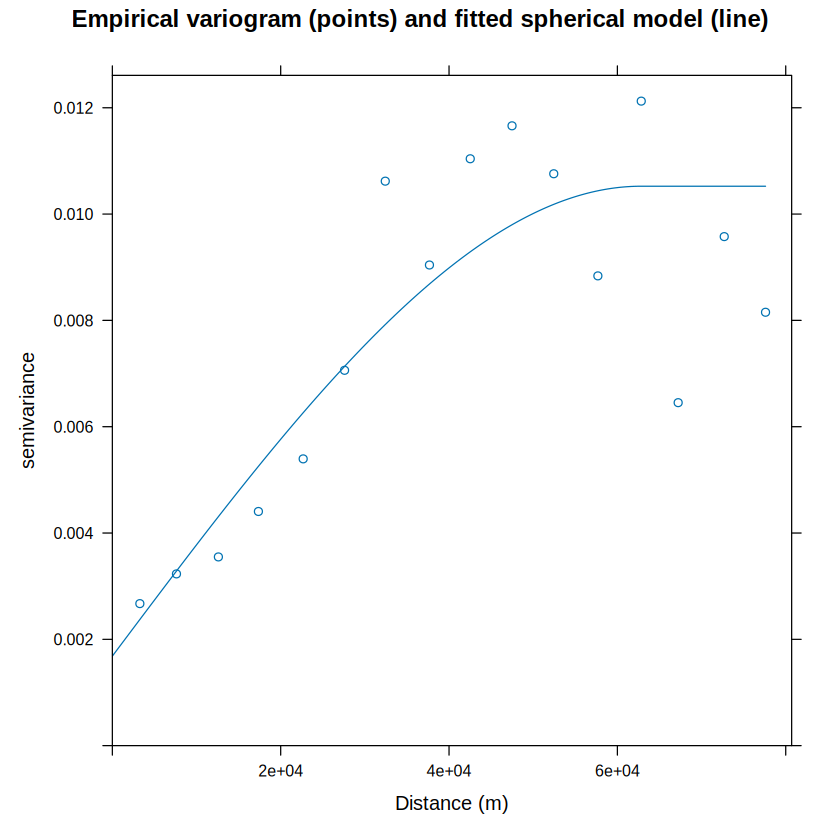

In [ ]:
v  <- variogram(prev ~ 1, mis_sf, cutoff = 80000, width = 5000)
v
vm <- fit.variogram(v, model = vgm(psill = 0.01, model = "Sph", range = 35000, nugget = 0.002))
vm
plot(v, vm, main = "Empirical variogram (points) and fitted spherical model (line)", xlab = "Distance (m)")

Look at the plot: the fitted line rises then flattens. np is the number of pairs in each bin; bins with few pairs (the first one has 17) are less reliable. If the points scattered with no rise, there would be no spatial structure and kriging would add nothing over the mean.

Step 4. Ordinary kriging with its variance.

[using ordinary kriging]


ERROR while rich displaying an object: Error in loadNamespace(x): there is no package called ‘geojsonio’

Traceback:
1. sapply(x, f, simplify = simplify)
2. lapply(X = X, FUN = FUN, ...)
3. FUN(X[[i]], ...)
4. tryCatch(withCallingHandlers({
 .     if (!mime %in% names(repr::mime2repr)) 
 .         stop("No repr_* for mimetype ", mime, " in repr::mime2repr")
 .     rpr <- repr::mime2repr[[mime]](obj)
 .     if (is.null(rpr)) 
 .         return(NULL)
 .     prepare_content(is.raw(rpr), rpr)
 . }, error = error_handler), error = outer_handler)
5. tryCatchList(expr, classes, parentenv, handlers)
6. tryCatchOne(expr, names, parentenv, handlers[[1L]])
7. doTryCatch(return(expr), name, parentenv, handler)
8. withCallingHandlers({
 .     if (!mime %in% names(repr::mime2repr)) 
 .         stop("No repr_* for mimetype ", mime, " in repr::mime2repr")
 .     rpr <- repr::mime2repr[[mime]](obj)
 .     if (is.null(rpr)) 
 .         return(NULL)
 .     prepare_content(is.raw(rpr), rpr)
 . }, error = 

,var1.pred,var1.var,geometry
,<dbl>,<dbl>,<POINT [m]>
1,0.1307816,0.005698076,POINT (691027.3 1139298)
2,0.1315680,0.005687193,POINT (693027.3 1139298)
3,0.1280769,0.005088629,POINT (691027.3 1141298)
4,0.1290566,0.005062639,POINT (693027.3 1141298)
5,0.1310667,0.005208800,POINT (695027.3 1141298)
6,0.1283274,0.005369815,POINT (685027.3 1143298)


   Min. 1st Qu.  Median    Mean 3rd Qu.    Max. 
0.07721 0.15672 0.21849 0.22289 0.26321 0.43985 

   Min. 1st Qu.  Median    Mean 3rd Qu.    Max. 
0.04919 0.05748 0.06076 0.06207 0.06571 0.08652 

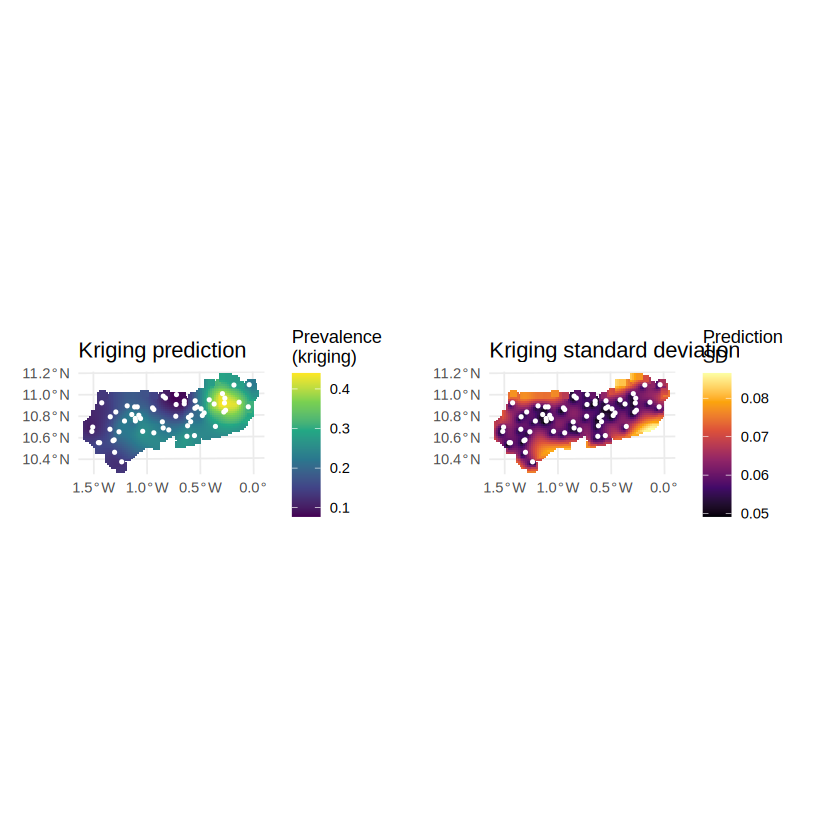

In [ ]:
kr <- krige(prev ~ 1, locations = mis_sf, newdata = grid, model = vm)
head(kr); summary(kr$var1.pred); summary(sqrt(kr$var1.var))

a <- ggplot(kr) + geom_sf(aes(colour = var1.pred), size = 1.6, shape = 15) +
  scale_colour_viridis_c("Prevalence\n(kriging)") + geom_sf(data = mis_sf, colour = "white", size = 0.8) +
  labs(title = "Kriging prediction") + theme_minimal()
b <- ggplot(kr) + geom_sf(aes(colour = sqrt(var1.var)), size = 1.6, shape = 15) +
  scale_colour_viridis_c("Prediction\nSD", option = "B") + geom_sf(data = mis_sf, colour = "white", size = 0.8) +
  labs(title = "Kriging standard deviation") + theme_minimal()
a + b

Step 5. Cross-validation to compare IDW and kriging.

In [ ]:
cv_kr  <- krige.cv(prev ~ 1, mis_sf, model = vm)
cv_idw <- krige.cv(prev ~ 1, mis_sf, set = list(idp = 2))   # IDW when no model is given
sqrt(mean(cv_kr$residual^2))     # kriging RMSE
sqrt(mean(cv_idw$residual^2))    # IDW RMSE

[1] 0.05276667

[1] 0.06152109

Step 6. Answer the Director's question: prevalence at Zebilla.

In [ ]:
zebilla <- st_sfc(st_point(c(-0.4767, 11.0)), crs = 4326) |> st_transform(32630) |> st_as_sf()
zb <- krige(prev ~ 1, mis_sf, newdata = zebilla, model = vm)
zb
cat("Prediction:", round(zb$var1.pred, 3), " SD:", round(sqrt(zb$var1.var), 3))

[using ordinary kriging]


ERROR while rich displaying an object: Error in loadNamespace(x): there is no package called ‘geojsonio’

Traceback:
1. sapply(x, f, simplify = simplify)
2. lapply(X = X, FUN = FUN, ...)
3. FUN(X[[i]], ...)
4. tryCatch(withCallingHandlers({
 .     if (!mime %in% names(repr::mime2repr)) 
 .         stop("No repr_* for mimetype ", mime, " in repr::mime2repr")
 .     rpr <- repr::mime2repr[[mime]](obj)
 .     if (is.null(rpr)) 
 .         return(NULL)
 .     prepare_content(is.raw(rpr), rpr)
 . }, error = error_handler), error = outer_handler)
5. tryCatchList(expr, classes, parentenv, handlers)
6. tryCatchOne(expr, names, parentenv, handlers[[1L]])
7. doTryCatch(return(expr), name, parentenv, handler)
8. withCallingHandlers({
 .     if (!mime %in% names(repr::mime2repr)) 
 .         stop("No repr_* for mimetype ", mime, " in repr::mime2repr")
 .     rpr <- repr::mime2repr[[mime]](obj)
 .     if (is.null(rpr)) 
 .         return(NULL)
 .     prepare_content(is.raw(rpr), rpr)
 . }, error = 

,var1.pred,var1.var,geometry
,<dbl>,<dbl>,<POINT [m]>
1,0.2279802,0.004570883,POINT (775738.2 1217139)


Prediction: 0.228  SD: 0.068

## 3.8 Trial test 3

Answer the trial test on paper (manual section 3.8). Answers are at the end of the manual.

# Topic 4 – Multi-Criteria Risk Mapping and Site Suitability

## 4.4 Step by step in R with Ama's data

Step 1. Read the indicator table and check it.

In [ ]:
ind <- read_csv(file.path(data_dir, "district_indicators.csv"))
head(ind); summary(ind)
ind |> filter(if_any(everything(), is.na))    # any missing values must be fixed first

Rows: 260 Columns: 6
── Column specification ────────────────────────────────────────────────────────
Delimiter: ","
chr (1): adm2_code
dbl (5): incidence_1000, rain_mm, ndvi, pop_density, facility_per_10k

ℹ Use `spec()` to retrieve the full column specification for this data.
ℹ Specify the column types or set `show_col_types = FALSE` to quiet this message.


adm2_code,incidence_1000,rain_mm,ndvi,pop_density,facility_per_10k
<chr>,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>
GH001,163.1,1706,0.469,95.3,0.60
GH002,152.6,1729,0.489,94.0,0.00
GH003,95.6,1678,0.450,90.3,0.71
GH004,127.5,1704,0.467,91.7,0.00
GH005,198.8,1660,0.454,88.0,0.27
GH006,65.9,1659,0.469,91.7,0.67


     adm2_code   incidence_1000      rain_mm          ndvi       
 Length   :260   Min.   : 13.80   Min.   :1231   Min.   :0.2700  
 N.unique :260   1st Qu.: 97.47   1st Qu.:1593   1st Qu.:0.4100  
 N.blank  :  0   Median :137.35   Median :1724   Median :0.4810  
 Min.nchar:  5   Mean   :141.03   Mean   :1672   Mean   :0.4536  
 Max.nchar:  5   3rd Qu.:167.32   3rd Qu.:1816   3rd Qu.:0.5122  
                 Max.   :352.10   Max.   :2032   Max.   :0.5650  
  pop_density      facility_per_10k
 Min.   :   82.7   Min.   :0.0000  
 1st Qu.:   91.3   1st Qu.:0.2100  
 Median :   95.1   Median :0.3350  
 Mean   :  452.7   Mean   :0.3498  
 3rd Qu.:  164.8   3rd Qu.:0.4500  
 Max.   :23913.3   Max.   :1.3200  

adm2_code,incidence_1000,rain_mm,ndvi,pop_density,facility_per_10k
<chr>,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>


Step 2. Normalise each indicator to 0-1 in the priority direction.

### Visual explainer: Building a malaria priority index

*This visual explains normalization, weighting, weighted sums and sensitivity analysis for the priority index.*

<div style="text-align:center; margin: 12px 0 24px 0;">
  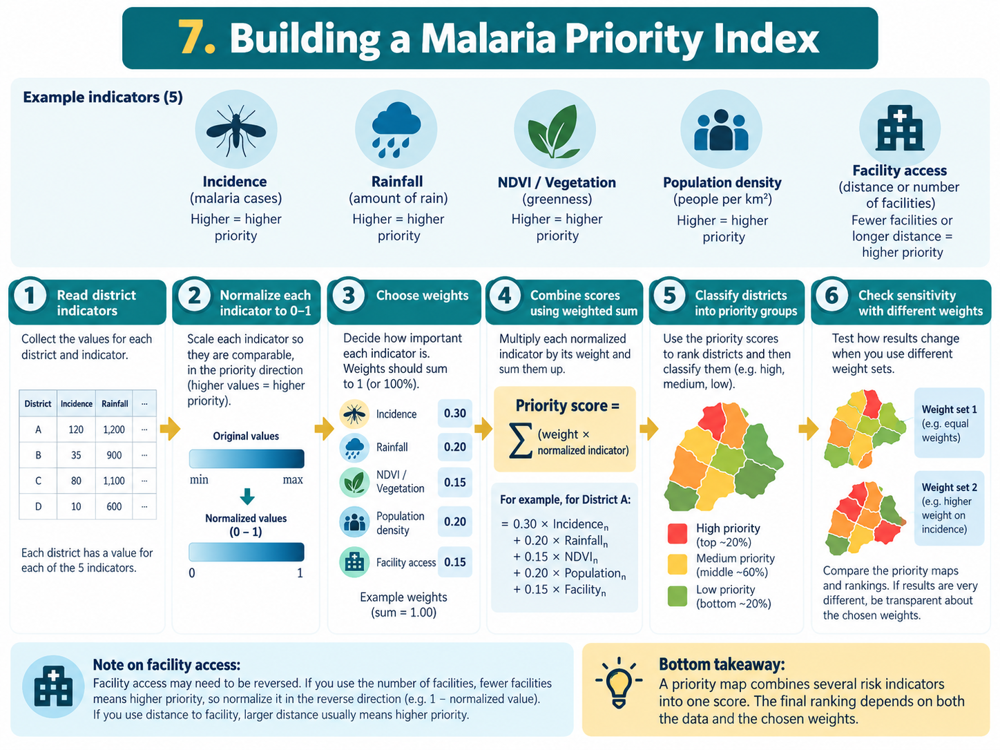
</div>


In [ ]:
ind_n <- ind |>
  mutate(n_inc  = rescale(incidence_1000),
         n_rain = rescale(rain_mm),
         n_ndvi = rescale(ndvi),
         n_dens = rescale(pop_density),
         n_fac  = 1 - rescale(facility_per_10k))    # reversed: more facilities = lower priority
ind_n |> select(adm2_code, n_inc, n_rain, n_ndvi, n_dens, n_fac) |> head()

adm2_code,n_inc,n_rain,n_ndvi,n_dens,n_fac
<chr>,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>
GH001,0.4413243,0.5930087,0.6745763,0.0005287320,0.5454545
GH002,0.4102867,0.6217228,0.7423729,0.0004741803,1.0000000
GH003,0.2417972,0.5580524,0.6101695,0.0003189177,0.4621212
GH004,0.3360922,0.5905119,0.6677966,0.0003776657,1.0000000
GH005,0.5468519,0.5355805,0.6237288,0.0002224031,0.7954545
GH006,0.1540053,0.5343321,0.6745763,0.0003776657,0.4924242


Notice n_dens: almost every district is close to 0 because one district (Accra Metropolis, 23,913 people per km2) sets the maximum. Min-max scaling is sensitive to extreme values; a rank or a log transform is an alternative when one unit dominates. We keep min-max here so that the effect is visible.

Step 3. Weights. Start with the panel's AHP weights; keep equal weights and a burden-heavy set for sensitivity.

In [ ]:
w_ahp    <- c(n_inc = 0.45, n_rain = 0.15, n_ndvi = 0.15, n_dens = 0.10, n_fac = 0.15)
w_equal  <- c(n_inc = 0.20, n_rain = 0.20, n_ndvi = 0.20, n_dens = 0.20, n_fac = 0.20)
w_burden <- c(n_inc = 0.70, n_rain = 0.10, n_ndvi = 0.10, n_dens = 0.05, n_fac = 0.05)
sum(w_ahp); sum(w_equal); sum(w_burden)       # each must be 1

[1] 1

[1] 1

[1] 1

Step 4. Weighted linear combination and classes.


 Very low       Low    Medium      High Very high 
       52        52        52        52        52 

,adm2_name,region,index_ahp,class_ahp
,<chr>,<chr>,<dbl>,<fct>
1,Effia Kwesimintsim Municipal,Western,0.6731724,Very high
2,Adansi North,Ashanti,0.6423301,Very high
3,Tarkwa Nsuaem,Western,0.6351772,Very high
4,Ahanta West Municipal,Western,0.6329429,Very high
5,Abura-asebu-kwamankese,Central,0.6273111,Very high
6,Birim Central Municipal,Eastern,0.6184877,Very high
7,Lower Manya,Eastern,0.6076632,Very high
8,Mpohor,Western,0.6021387,Very high
9,Suhum Municipal,Eastern,0.5979654,Very high


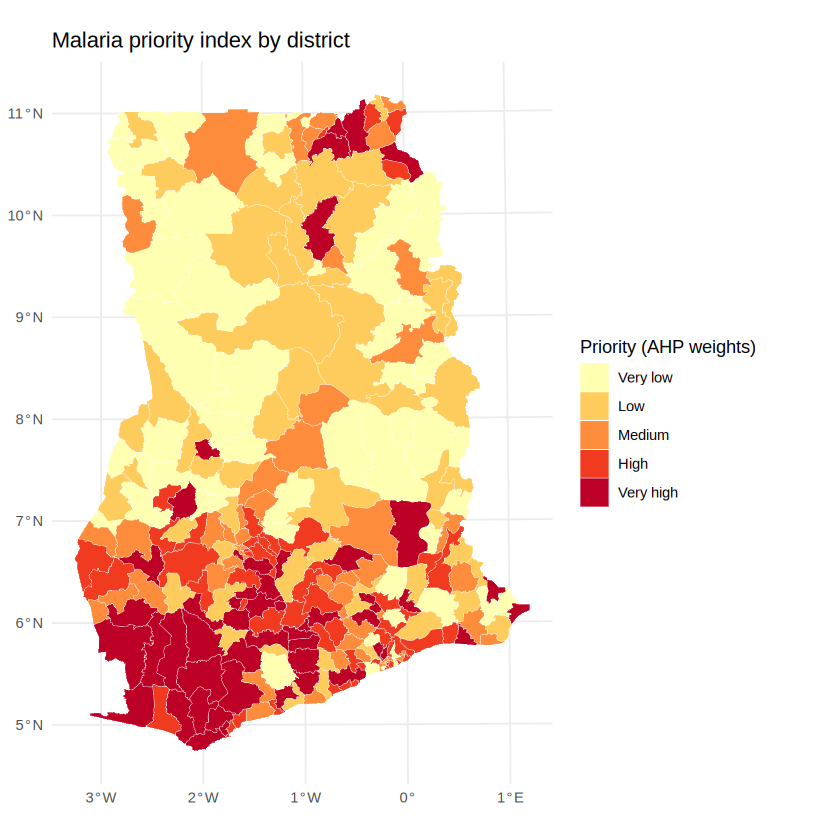

In [ ]:
score <- function(df, w) rowSums(as.matrix(df[names(w)]) * matrix(w, nrow(df), length(w), byrow = TRUE))

ind_n <- ind_n |>
  mutate(index_ahp    = score(ind_n, w_ahp),
         index_equal  = score(ind_n, w_equal),
         index_burden = score(ind_n, w_burden),
         class_ahp    = cut(index_ahp, breaks = quantile(index_ahp, c(0, .2, .4, .6, .8, 1)),
                            labels = c("Very low", "Low", "Medium", "High", "Very high"),
                            include.lowest = TRUE))
table(ind_n$class_ahp)

map_idx <- districts_utm |> left_join(ind_n, by = "adm2_code")
map_idx |> st_drop_geometry() |> arrange(desc(index_ahp)) |>
  select(adm2_name, region, index_ahp, class_ahp) |> head(10)

ggplot(map_idx) + geom_sf(aes(fill = class_ahp), colour = "white", linewidth = 0.1) +
  scale_fill_brewer("Priority (AHP weights)", palette = "YlOrRd") +
  labs(title = "Malaria priority index by district") + theme_minimal()

Stop and think about that map. Incidence is highest in the north (Topic 2), yet the priority map points south-west. The reason is in the weights: 0.45 for incidence, but 0.30 for two environmental indicators that both peak in the forest zone, and the northern districts score near zero on both. Whether that is right is a programme decision, not a statistical one; the index has made the decision visible. If the Director's intention is to spray where transmission is highest now, the burden-heavy weights are the better choice. This is exactly why Step 5 exists.

Step 5. Sensitivity: which districts are in the top 20 under every weighting?

[1] 5

adm2_name,index_ahp,top_equal,top_burden,robust
<chr>,<dbl>,<lgl>,<lgl>,<lgl>
Effia Kwesimintsim Municipal,0.6731724,TRUE,TRUE,TRUE
Adansi North,0.6423301,TRUE,TRUE,TRUE
Tarkwa Nsuaem,0.6351772,TRUE,TRUE,TRUE
Ahanta West Municipal,0.6329429,TRUE,TRUE,TRUE
Abura-asebu-kwamankese,0.6273111,FALSE,TRUE,FALSE
Birim Central Municipal,0.6184877,TRUE,TRUE,TRUE
Lower Manya,0.6076632,FALSE,TRUE,FALSE
Mpohor,0.6021387,TRUE,FALSE,FALSE
Suhum Municipal,0.5979654,FALSE,TRUE,FALSE


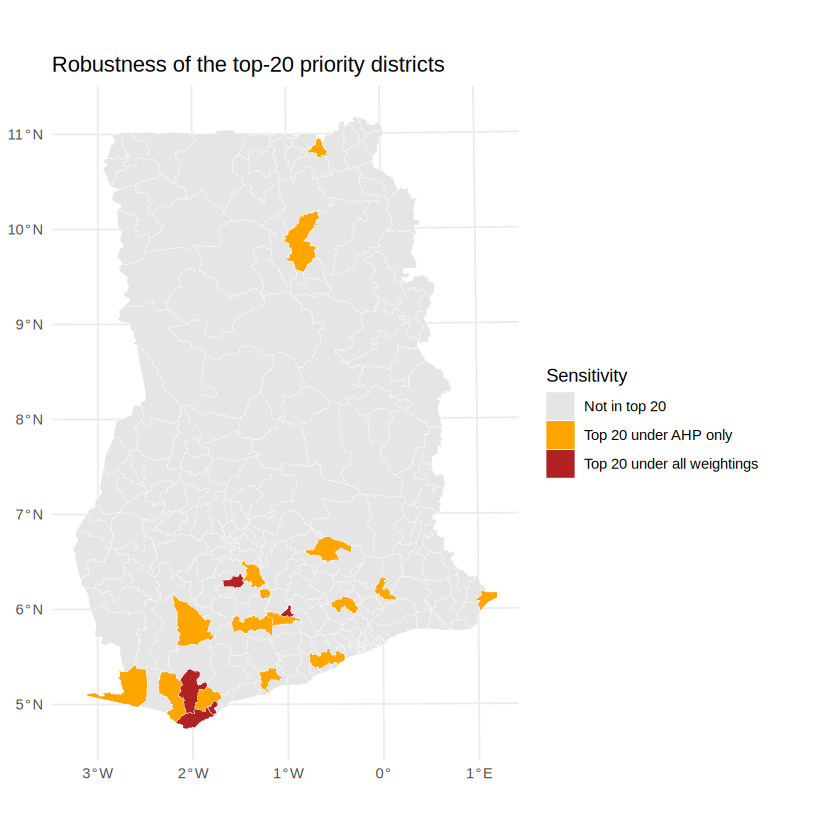

In [ ]:
top20 <- function(x) rank(-x) <= 20
ind_n <- ind_n |>
  mutate(top_ahp = top20(index_ahp), top_equal = top20(index_equal), top_burden = top20(index_burden),
         robust  = top_ahp & top_equal & top_burden)
sum(ind_n$robust)                           # districts in the top 20 under all three
map_idx <- districts_utm |> left_join(ind_n, by = "adm2_code")
map_idx |> st_drop_geometry() |> filter(top_ahp) |> arrange(desc(index_ahp)) |>
  select(adm2_name, index_ahp, top_equal, top_burden, robust)

ggplot(map_idx) +
  geom_sf(aes(fill = case_when(robust ~ "Top 20 under all weightings",
                               top_ahp ~ "Top 20 under AHP only",
                               TRUE ~ "Not in top 20")), colour = "white", linewidth = 0.1) +
  scale_fill_manual("Sensitivity", values = c("Top 20 under all weightings" = "firebrick",
                                              "Top 20 under AHP only" = "orange",
                                              "Not in top 20" = "grey90")) +
  labs(title = "Robustness of the top-20 priority districts") + theme_minimal()

## 4.8 Trial test 4

Answer the trial test on paper (manual section 4.8). Answers are at the end of the manual.

# Topic 5 – Raster Analysis and Environmental Exposure

## 5.4 Step by step in R with Ama's data

Step 1. Read, inspect and align. Printing a raster shows its dimensions, resolution, extent and CRS; summary() shows the values and therefore the units.

### Visual explainer: Raster analysis basics

*This visual introduces raster cells, alignment, map algebra and zonal statistics.*

<div style="text-align:center; margin: 12px 0 24px 0;">
  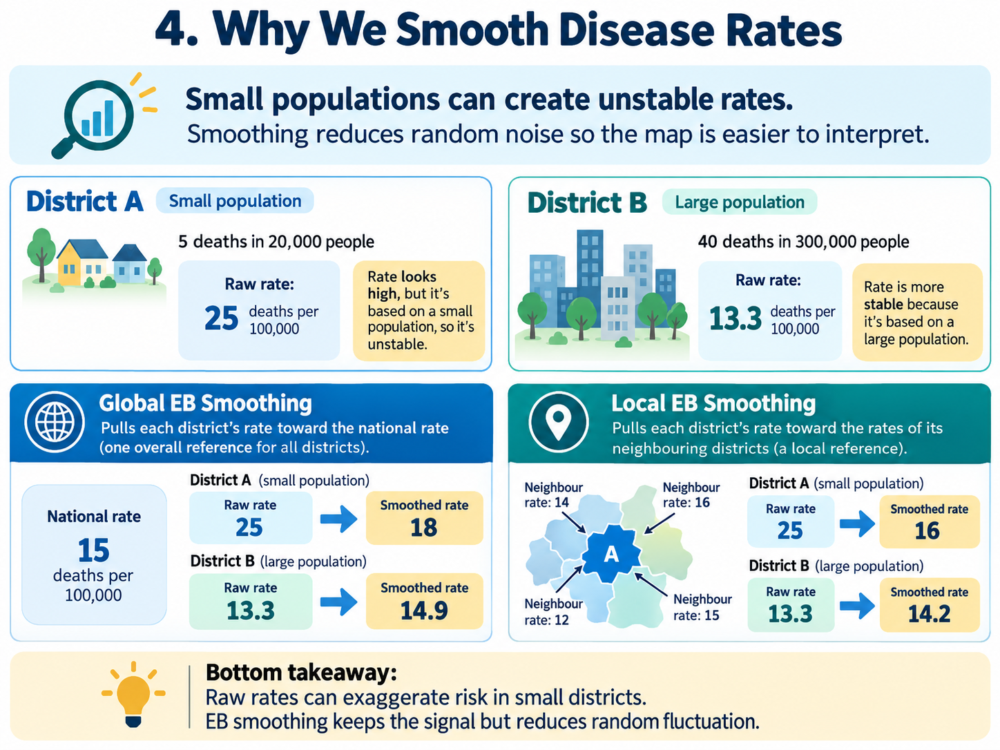
</div>


In [ ]:
rain_files <- list.files(file.path(data_dir, "rasters"), pattern = "chirps_2024", full.names = TRUE)
temp_files <- list.files(file.path(data_dir, "rasters"), pattern = "era5_temp_2024", full.names = TRUE)

rain <- rast(rain_files);  names(rain) <- paste0("rain_", sprintf("%02d", 1:12))
temp <- rast(temp_files);  names(temp) <- paste0("temp_", sprintf("%02d", 1:12))
ndvi <- rast(file.path(data_dir, "rasters/ndvi_2024.tif"))
elev <- rast(file.path(data_dir, "rasters/srtm_ghana.tif"))

rain            # 12 layers, 0.05 degree (about 5 km)
elev            # 1 layer, 0.01 degree (about 1 km): different resolution
summary(temp[[1]])     # values near 299: kelvin

class       : SpatRaster
size        : 130, 91, 12  (nrow, ncol, nlyr)
resolution  : 0.05, 0.05  (x, y)
extent      : -3.3, 1.25, 4.7, 11.2  (xmin, xmax, ymin, ymax)
coord. ref. : lon/lat WGS 84 (EPSG:4326)
sources     : chirps_2024_01.tif
              chirps_2024_02.tif
              chirps_2024_03.tif
              ... and 9 more sources
names       :   rain_01,   rain_02,    rain_03,    rain_04,    rain_05,    rain_06, ...
min values  :         0,         0,  11.972803,  46.836063, 106.775612, 154.303482, ...
max values  : 42.210255, 62.759277, 125.211067, 210.080063,  320.31842, 373.616699, ...

class       : SpatRaster
size        : 650, 455, 1  (nrow, ncol, nlyr)
resolution  : 0.01, 0.01  (x, y)
extent      : -3.3, 1.25, 4.7, 11.2  (xmin, xmax, ymin, ymax)
coord. ref. : lon/lat WGS 84 (EPSG:4326)
source      : srtm_ghana.tif
name        : elevation_m
min value   :  111.995712
max value   :  493.853668

    temp_01     
 Min.   :297.2  
 1st Qu.:299.1  
 Median :299.5  
 Mean   :299.5  
 3rd Qu.:299.9  
 Max.   :300.7  
 NAs    :3909   

[1] TRUE

    temp_01     
 Min.   :24.05  
 1st Qu.:25.97  
 Median :26.31  
 Mean   :26.34  
 3rd Qu.:26.75  
 Max.   :27.52  
 NAs    :3909   

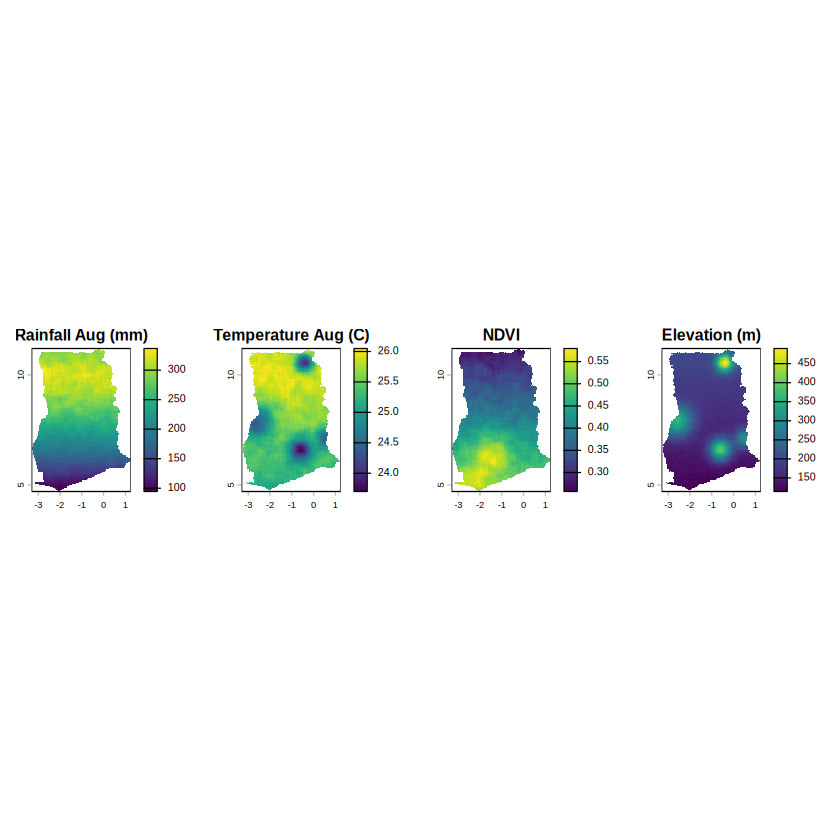

In [ ]:
temp <- temp - 273.15                  # kelvin -> Celsius, all 12 layers at once

template <- rain[[1]]                  # rainfall is the coarsest: bring the others to it
temp_a <- resample(temp, template, method = "bilinear")
ndvi_a <- resample(ndvi, template, method = "bilinear")
elev_a <- resample(elev, template, method = "bilinear")
compareGeom(rain, temp_a, ndvi_a, elev_a)      # TRUE = aligned
summary(temp_a[[1]])

par(mfrow = c(1, 4), mar = c(1, 1, 2, 3))
plot(rain[[8]], main = "Rainfall Aug (mm)"); plot(temp_a[[8]], main = "Temperature Aug (C)")
plot(ndvi_a, main = "NDVI"); plot(elev_a, main = "Elevation (m)")
par(mfrow = c(1, 1))

Step 2. Map algebra and reclassification: annual means, the four suitability rules, the count of suitable months, and elevation classes.

,layer,value,count
,<dbl>,<dbl>,<dbl>
1,1,0.75,3751
2,1,1.00,4170


class       : SpatRaster
size        : 130, 91, 1  (nrow, ncol, nlyr)
resolution  : 0.05, 0.05  (x, y)
extent      : -3.3, 1.25, 4.7, 11.2  (xmin, xmax, ymin, ymax)
coord. ref. : lon/lat WGS 84 (EPSG:4326)
source(s)   : memory
name        : suitable_months
min value   :               6
max value   :              10

,layer,value,count
,<dbl>,<dbl>,<dbl>
1,1,6,2761
2,1,7,2935
3,1,8,423
4,1,9,1715
5,1,10,87


,layer,value,count
,<dbl>,<dbl>,<dbl>
1,1,1,7423
2,1,2,498


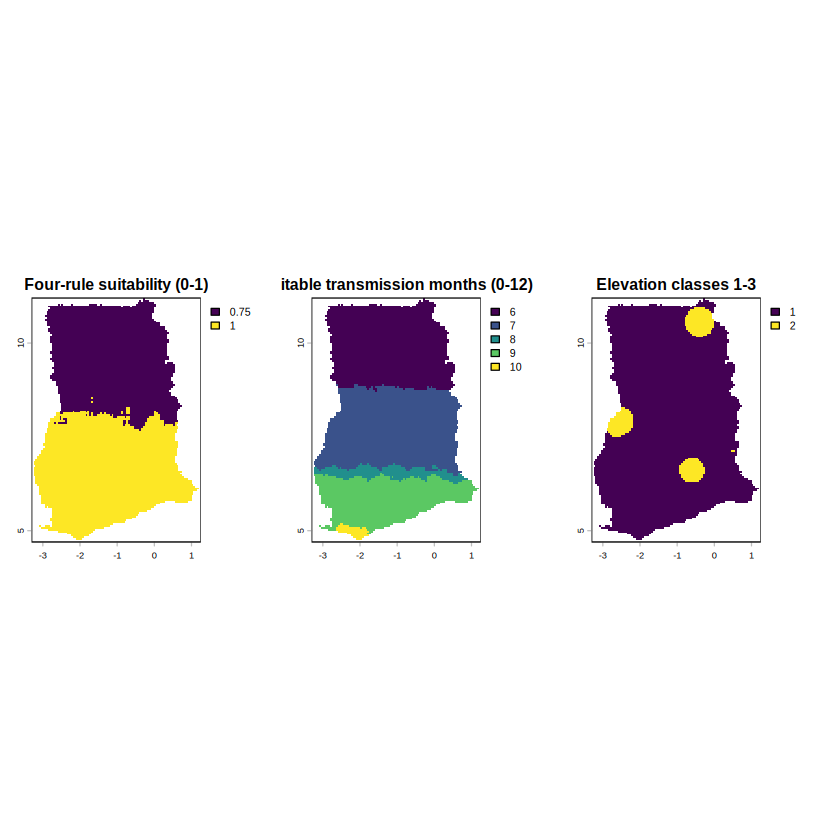

In [ ]:
rain_mean <- app(rain, mean)           # mean monthly rainfall, mm
temp_mean <- app(temp_a, mean)

ok_temp <- (temp_mean >= 18) & (temp_mean <= 32)
ok_rain <- rain_mean >= 100
ok_ndvi <- ndvi_a >= 0.4
ok_elev <- elev_a < 1000

score <- function(ok) ifel(ok, 1, 0)   # TRUE/FALSE -> 1/0; adding TRUE/FALSE rasters directly gives OR
suit4 <- (score(ok_temp) + score(ok_rain) + score(ok_ndvi) + score(ok_elev)) / 4
freq(suit4, digits = 2)

# a more informative version: how many months meet the temperature AND rainfall rules?
suit_monthly <- ((temp_a >= 18) & (temp_a <= 32)) & (rain >= 80)
names(suit_monthly) <- month.abb
suit <- app(suit_monthly, sum); names(suit) <- "suitable_months"
suit; freq(suit)

rcl <- matrix(c(-Inf, 300, 1,   300, 600, 2,   600, Inf, 3), ncol = 3, byrow = TRUE)   # from, to, class
elev_class <- classify(elev_a, rcl)
freq(elev_class)

par(mfrow = c(1, 3), mar = c(1, 1, 2, 3))
plot(suit4, main = "Four-rule suitability (0-1)"); plot(suit, main = "Suitable transmission months (0-12)")
plot(elev_class, main = "Elevation classes 1-3")
par(mfrow = c(1, 1))

The four-rule score takes only two values because three of the four rules are met everywhere in Ghana; the monthly count is the more useful product. freq() rounds values to whole numbers unless you give digits, which is why digits = 2 is needed for a raster of fractions.

Step 3. The temporal stack: which months are suitable where, and the rainfall time series of each Upper East district.

  |======================================================================| 100%


,mean.rain_01,mean.rain_02,mean.rain_03,mean.rain_04,mean.rain_05,mean.rain_06,mean.rain_07,mean.rain_08,mean.rain_09,mean.rain_10,mean.rain_11,mean.rain_12
,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>
1,0,0,12,49,113,161,210,298,249,111,25,12
2,0,0,13,50,113,164,211,301,252,111,25,13
3,0,0,12,49,112,162,209,293,252,110,25,12
4,0,0,12,50,113,162,216,297,255,110,25,12


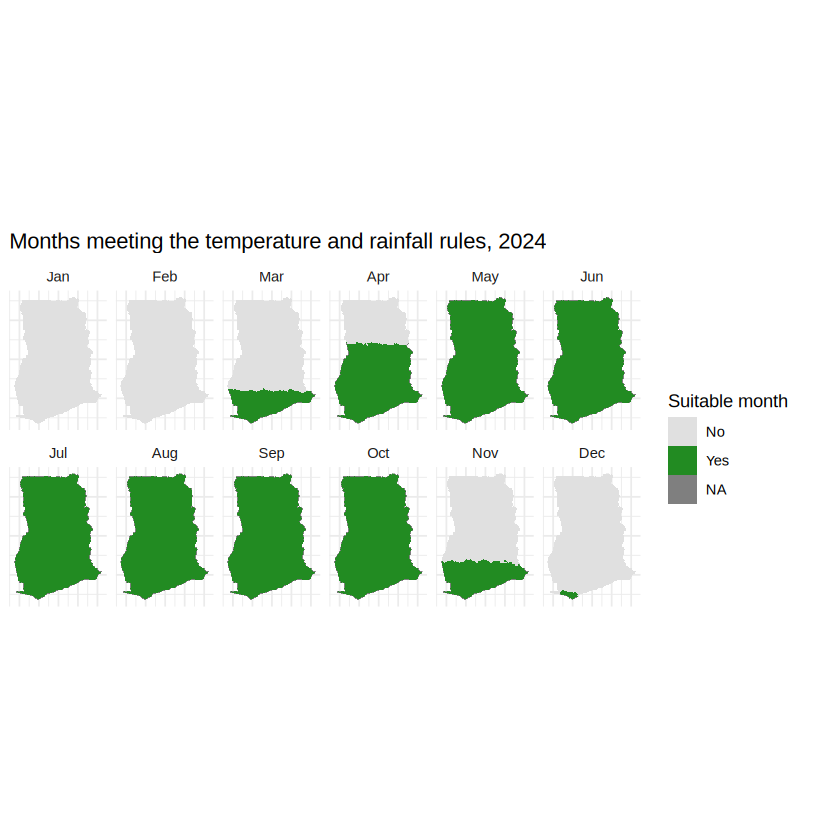

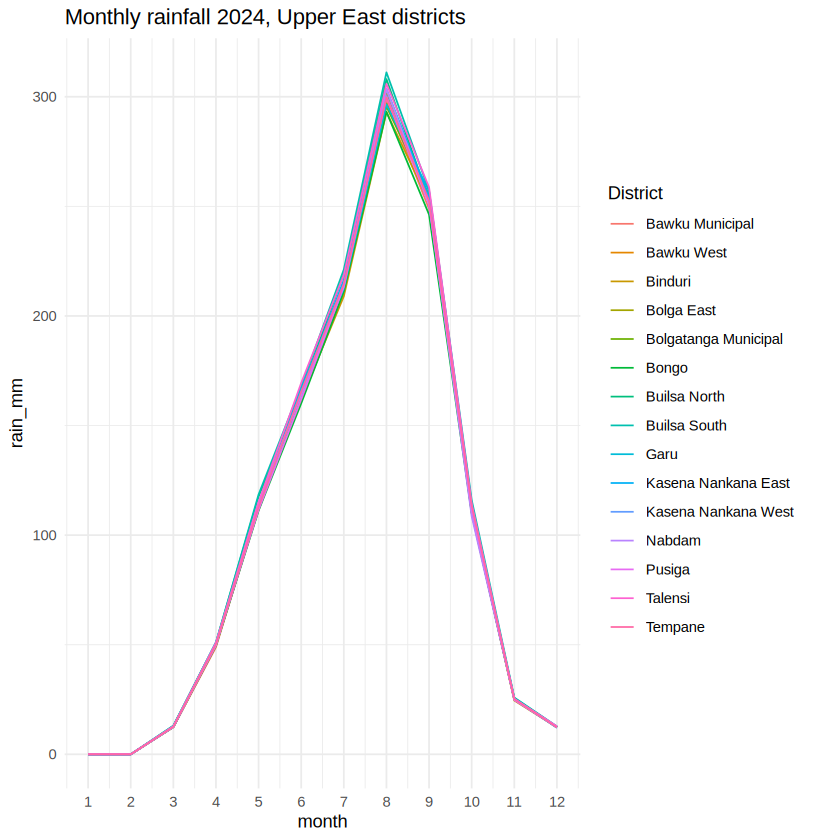

In [ ]:
sm <- as.data.frame(suit_monthly * 1, xy = TRUE) |>
  pivot_longer(-c(x, y), names_to = "month", values_to = "suitable") |>
  mutate(month = factor(month, month.abb), suitable = factor(suitable, c(0, 1), c("No", "Yes")))
ggplot(sm) + geom_raster(aes(x, y, fill = suitable)) + facet_wrap(~month, ncol = 6) + coord_equal() +
  scale_fill_manual("Suitable month", values = c("No" = "grey88", "Yes" = "forestgreen")) +
  labs(title = "Months meeting the temperature and rainfall rules, 2024", x = NULL, y = NULL) +
  theme_minimal() + theme(axis.text = element_blank())

ue_poly <- districts_utm |> filter(region == "Upper East") |> st_transform(crs(rain))
ue_rain <- exact_extract(rain, ue_poly, "mean")     # 12 columns, one per month
round(head(ue_rain, 4))

ue_rain |> mutate(adm2_name = ue_poly$adm2_name) |>
  pivot_longer(-adm2_name, names_to = "month", values_to = "rain_mm") |>
  mutate(month = as.integer(str_extract(month, "\\d+"))) |>
  ggplot(aes(month, rain_mm, colour = adm2_name)) + geom_line() + scale_x_continuous(breaks = 1:12) +
  labs(title = "Monthly rainfall 2024, Upper East districts", colour = "District") + theme_minimal()

Step 4. Zonal statistics to all districts, and extraction at facilities and cases.

  |======================================================================| 100%
  |======================================================================| 100%
  |======================================================================| 100%
  |======================================================================| 100%
  |======================================================================| 100%


,adm2_name,rain_mm_mean,temp_c_mean,ndvi_mean,elev_mean,suit_mean
,<chr>,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>
1,Asunafo North Municipal,142.1322,27.21601,0.4693065,164.7846,7.165664
2,Asunafo South,144.1063,27.27954,0.4887199,145.5734,7.868759
3,Asutifi North,139.8282,27.06439,0.4504234,196.8583,7.000000
4,Asutifi South,142.0107,27.19728,0.4673023,165.9029,7.000000
5,Tano North Municipal,138.3633,27.08108,0.4536346,197.8453,7.000000
6,Tano South Municipal,138.2360,27.18669,0.4688466,182.4383,7.000000


Rows: 900 Columns: 4
── Column specification ────────────────────────────────────────────────────────
Delimiter: ","
chr (2): facility_name, type
dbl (2): lon, lat

ℹ Use `spec()` to retrieve the full column specification for this data.
ℹ Specify the column types or set `show_col_types = FALSE` to quiet this message.


  |======================================================================| 100%


facility_name,type,suit_here,rain_2km
<chr>,<chr>,<dbl>,<dbl>
Facility 1,CHPS,7,135.6329
Facility 2,Health Centre,6,103.0336
Facility 3,CHPS,7,135.5185
Facility 4,Clinic,9,151.9050
Facility 5,Clinic,6,106.9442


   Min. 1st Qu.  Median    Mean 3rd Qu.    Max. 
  215.0   233.2   241.2   240.5   249.8   262.0 

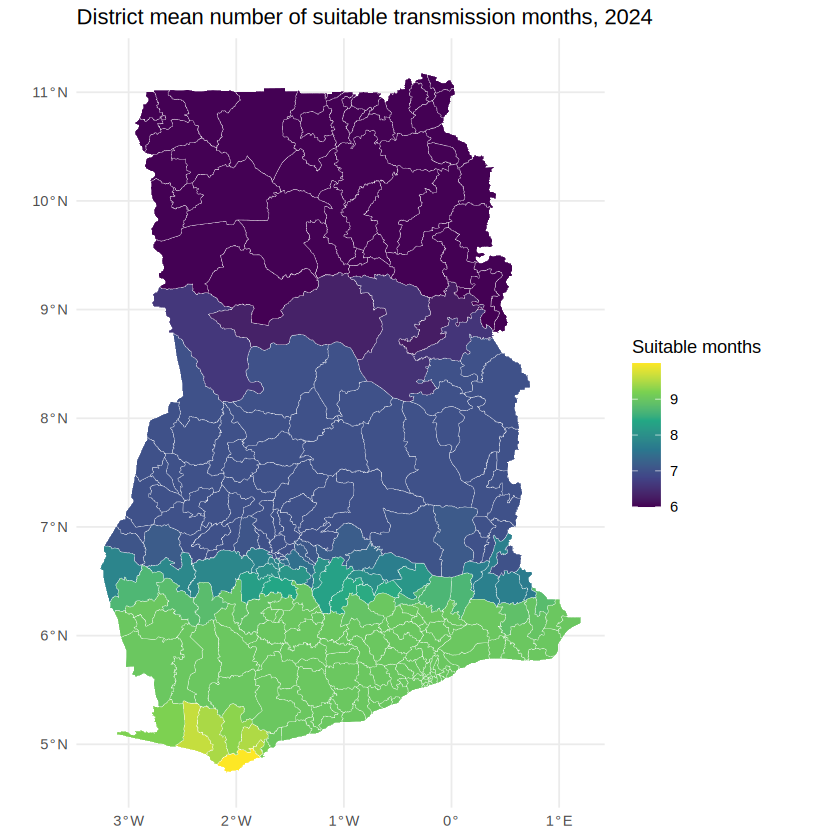

In [ ]:
d_wgs <- st_transform(districts_utm, crs(rain))      # polygons must be in the raster's CRS
d_env <- d_wgs |>
  mutate(rain_mm_mean = exact_extract(rain_mean, d_wgs, "mean"),
         temp_c_mean  = exact_extract(temp_mean, d_wgs, "mean"),
         ndvi_mean    = exact_extract(ndvi_a,   d_wgs, "mean"),
         elev_mean    = exact_extract(elev_a,   d_wgs, "mean"),
         suit_mean    = exact_extract(suit,     d_wgs, "mean"))
d_env |> st_drop_geometry() |> select(adm2_name, rain_mm_mean, temp_c_mean, ndvi_mean, elev_mean, suit_mean) |> head(6)

fac <- read_csv(file.path(data_dir, "facilities.csv")) |> st_as_sf(coords = c("lon", "lat"), crs = 4326)
fac$suit_here <- terra::extract(suit, vect(fac))[, 2]                       # value under the point
fac$rain_2km  <- exact_extract(rain_mean,                                    # mean within 2 km
                               st_buffer(st_transform(fac, 32630), 2000) |> st_transform(crs(rain)), "mean")
head(st_drop_geometry(fac), 5)

cases_wgs <- st_transform(cases_sf, crs(elev))
cases_wgs$elev_m <- terra::extract(elev, vect(cases_wgs))[, 2]
summary(cases_wgs$elev_m)

ggplot(d_env) + geom_sf(aes(fill = suit_mean), colour = "white", linewidth = 0.1) +
  scale_fill_viridis_c("Suitable months") +
  labs(title = "District mean number of suitable transmission months, 2024") + theme_minimal()

Step 5. Hand the district table to Topic 4 and save it.

In [ ]:
dir.create("/content/outputs", showWarnings = FALSE)
d_env |> st_drop_geometry() |>
  select(adm2_code, rain_mm_mean, temp_c_mean, ndvi_mean, elev_mean, suit_mean) |>
  write_csv("/content/outputs/district_environment_2024.csv")
read_csv("/content/outputs/district_environment_2024.csv") |> head(3)

Rows: 260 Columns: 6
── Column specification ────────────────────────────────────────────────────────
Delimiter: ","
chr (1): adm2_code
dbl (5): rain_mm_mean, temp_c_mean, ndvi_mean, elev_mean, suit_mean

ℹ Use `spec()` to retrieve the full column specification for this data.
ℹ Specify the column types or set `show_col_types = FALSE` to quiet this message.


adm2_code,rain_mm_mean,temp_c_mean,ndvi_mean,elev_mean,suit_mean
<chr>,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>
GH001,142.1322,27.21601,0.4693065,164.7846,7.165664
GH002,144.1063,27.27954,0.4887199,145.5734,7.868759
GH003,139.8282,27.06439,0.4504234,196.8583,7.000000


## 5.8 Trial test 5

Answer the trial test on paper (manual section 5.8). Answers are at the end of the manual.

---
End of the module. Download anything you want to keep from the Files panel before the session ends.